# Совместное появление участников в шоу продакшена "Medium Quality"

>**Контекст**
>
>Medium Quality — продакшн-компания, производящая развлекательный видеоконтент, наиболее известная такими проектами как "Что было дальше?", "Натальная карта", "Внутри Лапенко" и другими. Основана бывшим генеральным продюсером телеканала ТНТ Вячеславом Дусмухаметовым в 2016 году. Основным направлением работы продакшена было производство развлекательных проектов для YouTube, однако в конце 2022 года корпорация VK приобрела 51% продакшена, а в феврале 2023 было объявлено о переносе проектов Medium Quality с YouTube на платформу VK Видео. Позже, в 2024, году YouTube был заблокирован властями на территории РФ. Так, с начала 2023 года на платформе VK Видео активно публикуются многочисленные проекты Medium Quality.

В социальных сетях нередко иронизируют на тему однообразного контента Medium Quality: большинство популярных шоу эксплуатируют одинаковые форматы, задействуя в них одних и тех же медийных лиц. В этом блокноте мы проверим последнее утверждение и ответим на следующие вопросы:

- какие участники чаще остальных появляются в разных шоу?
- какие особенности имеет рассматриваемая социальная сеть?
- какие сообщества и клики в ней обнаруживаются?

> **Вывод**
>
> Анализ рассматривает участие 3324 человек в 168 проектах продакшена за период с марта 2022 по декабрь 2025 года.
> Участие в проектах сконцентрировано внутри небольшого круга медийных личностей (чаще всего комиков, так или иначе связанных с проектами телеканала ТНТ): топ-5 участников появлялись в >30% шоу продакшена, в то время, как 90% участников участвовали в 4% шоу и меньше. В число этих топ-5 вошли Игорь Джабраилов, Павел Дедищев, Гурам Амарян, Дмитрий Позов, Саша Ваш. Совокупно топ-1% участников (13 человек) участвовали в 80% шоу.
>Такая неоднородность в количестве появлений в шоу выражается в особенностях структуры социальной сети. Так, сеть имеет структуру small-world, когда большинство участников имеет связь с любым другим через небольшое количество рукопожатий. Это обеспечивается во многом благодаря хабам -- чаще всего ведущих популярных шоу, которые в течение многих выпусков появляются вместе с другими участниками, либо участвуют в качестве приглашенного гостя. Такие участники имеют наибольшие значения мер центральности: degree, eigenvector, и betweenness.
> В сети удалось обнаружить 19 сообществ, но при этом сама сеть не фрагментирована.

Работа включает следующие этапы:
#### 1. Автоматизированный сбор данных.

Большим подспорьем при сборе данных стал сайт [Humorpedia](https://humorpedia.ru/medium-quality/), где перечислены проекты Medium Quality и ссылки на плейлисты с эпизодами шоу. Так как информация на сайте была не частично неактуальной, недостающие плейлисты были добавлены в датасет на основе принадлежности к каналам, которые перечислены на Humorpedia.

Сбор даных проходил в два этапа:
1) формирование списка шоу вручную с опорой на сайт Humorpedia
2) скрейпинг эпизодов указанных шоу с помощью самописного web-scraper'а ([ссылка на блокнот](https://github.com/liminovna/network-analysis-project/scraper.ipynb)). У ВК есть собственный API, но извлечь нужные данные в этой ситуации с помощью библиотеки `requests` было проще, чем использовать официальный API.
3) извлечение из описаний шоу и эпизодов ведущих и их гостей с помощью spacy, проверка и точечные дополнения/корректировки.

Данные в датасете актуальны на момент 2 декабря 2025 года. Продакшен также производит проекты и на других платформах -- они в датасет не вошли.

#### 2. Анализ и визуализация.

Анализ включает общее описание сети, определение хабов, структурный анализ,определение сообществ и клик.

В данной работе **вершинами** являются персоналии, а **ребрами** -- совместное появление в эпизоде. Граф является ненаправленным, гомогенным, взвешенным по количеству совместных появлений, или взаимодействий.

Собранные данные организованы в две таблицы:
- `data`: список эпизодов с указанием ведущих и гостей
    - `label` -- название лэйбла/канала (LABELSMART, Площадка, SlowSlowCow и др.)
    - `show_title` -- название шоу
    - `host_norm` -- ведущие
    - `link` -- ссылка на плейлист
    - `owner_id_y` -- id владельца плейлиста
    - `album_id` -- id плейлиста
    - `id` -- id видео
    - `title` -- название видео
    - `direct_url` -- ссылка на видео
    - `date` -- дата загрузки видео на платформу
    - `description` -- описание видео
    - `duration` -- длительность видео
    - `guests_full` -- список гостей
- `shows`: список шоу
    - `label` -- название лэйбла/канала (LABELSMART, Площадка, SlowSlowCow и др.)
    - `show_title` -- название шоу
    - `host_norm` -- ведущие
    - `link` -- ссылка на плейлист
    - `owner_id` -- id владельца плейлиста
    - `album_id` -- id плейлиста
    - `videos_count` -- количество видео в плейлисте
    - `status` -- предусмотрено ли участие "известных" гостей

Временные рамки анализа охватывают 2022-2025гг.

## Предобработка данных

In [ ]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

def str2list(x: str) -> list:
    """
    Конвертировать строковое значение из поля guests_full в список.
    Если конвертация невозможна, вывести это значение.
    """
    try:
        if x is not np.nan:
            res = ast.literal_eval(x)
            return list(map(lambda s: s.strip(), res))
    except:
        print('error', x)

        return ['error']

def get_upper_iqr_threshold(series: pd.Series, coeff=1.5) -> float:
    """
    Посчитать верхний порог для нахождения выбросов
    """
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    return q3 + coeff * iqr

In [ ]:
# Загружаем данные из гитхаб-репозитория
!wget https://github.com/liminovna/network-analysis-project/raw/refs/heads/main/mq_data.xlsx

--2026-11-08 11:17:10--  https://github.com/liminovna/network-analysis-project/raw/refs/heads/main/mq_data.xlsx
Resolving github.com (github.com)... 140.82.113.4
Connecting to github.com (github.com)|140.82.113.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/liminovna/network-analysis-project/refs/heads/main/mq_data.xlsx [following]
--2026-11-08 11:17:10--  https://raw.githubusercontent.com/liminovna/network-analysis-project/refs/heads/main/mq_data.xlsx
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1446877 (1.4M) [application/octet-stream]
Saving to: ‘mq_data.xlsx.1’

mq_data.xlsx.1      100%[===================>]   1.38M  --.-KB/s    in 0.03s   

2026-11-08 11:17:11 (41.0 MB/s) - ‘mq_data.

Извлекаем данные о шоу: из этого файла нам понадобится только название шоу `show_title` и колонка `status`, на основе которой мы будем избавляться от эпизодов, для которых не получилось определить "известных" участников

In [ ]:
# читаем файл
df_shows = pd.read_excel('mq_data.xlsx', sheet_name='shows', engine='openpyxl')
df_shows.shape

(188, 10)

In [ ]:
print('Всего шоу:', len(df_shows))

Всего шоу: 188


Избавляемся от шоу, где не получилось определить "известных" участников

In [ ]:
# читаем данные об эпизодах (=основной датасет) в датафрейм
cols = ['label', 'show_title', 'host_norm',
       'link', 'album_id', 'videos_count', 'id',
       'owner_id_y', 'title', 'direct_url', 'adding_date', 'date',
       'description', 'duration', 'guests_full']
df = pd.read_excel('mq_data.xlsx', sheet_name='data', engine='openpyxl')[cols]
df['date'] = pd.to_datetime(df['date'],unit='s')
df.shape

(3378, 15)

In [ ]:
# не для всех шоу удалось найти имена либо ведущих, либо гостей (в таблице для них не указан status) -- такие шоу мы удаляем из анализа
to_delete = df_shows[df_shows['status'].isna()]['show_title']
to_delete_df = df[df['show_title'].isin(to_delete)]
df.drop(to_delete_df.index, inplace=True)
df.shape

(3341, 15)

In [ ]:
# удаляем строки, где не указаны ни ведущие, ни гости по иным причинам (ссылка ведет на ютуб, нет постоянных ведущих и не указаны гости)
df.drop(df[(df['host_norm'].isna()) & (df['guests_full'].isna())].index, inplace=True)
df.shape

(3334, 15)

In [ ]:
# удаляем шоу, для которых не получилось извлечь названия эпизодов
df.drop(df[df['videos_count']==0].index, inplace=True)
df.shape

(3324, 15)

In [ ]:
print('Всего шоу после удаления "лишних" строк из датасета:', df['show_title'].nunique())

Всего шоу после удаления "лишних" строк из датасета: 168


## Разведочный анализ

Далее рассмотрим, какие данные нам доступны и составим общую картину об активности шоу и участников.

In [ ]:
df.head()

,label,show_title,host_norm,link,album_id,videos_count,id,owner_id_y,title,direct_url,adding_date,date,description,duration,guests_full
1,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239354.0,-214484275.0,[Культурный Код] - БЕЛАРУСЬ | [Культурный Код] #2,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:34:37,"Продолжаем узнавать из первых уст о культурах,...",435.0,['Ирина Приходько']
2,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239353.0,-214484275.0,[Культурный Код] - МЕДИЦИНА | [Культурный Код] #3,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:34:18,"Продолжаем узнавать из первых уст о культурах,...",462.0,['Лука Хиникадзе']
3,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239352.0,-214484275.0,[Культурный Код] - САНКТ-ПЕТЕРБУРГ | [Культурн...,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:33:35,"Продолжаем узнавать из первых уст о культурах,...",509.0,['Всеволод Ловкачев']
4,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239351.0,-214484275.0,[Культурный Код] - BURNING MAN | [Культурный к...,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:32:53,"Продолжаем узнавать из первых уст о культурах,...",776.0,['Павел Сахаров']
5,LABELSMART,[Культурный Код],NaN,https://vkvideo.ru/playlist/-214484275_12,12,9,456239350.0,-214484275.0,[Культурный Код] - ТАТУ | [Культурный код] #5,https://vkvideo.ru/playlist/-214484275_12/vide...,1.674470e+09,2023-01-23 10:32:42,"Продолжаем узнавать из первых уст о культурах,...",412.0,['Евген Сердюк']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3324 entries, 1 to 3377
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   label         3324 non-null   object        
 1   show_title    3324 non-null   object        
 2   host_norm     2985 non-null   object        
 3   link          3324 non-null   object        
 4   album_id      3324 non-null   object        
 5   videos_count  3324 non-null   int64         
 6   id            3324 non-null   float64       
 7   owner_id_y    3324 non-null   float64       
 8   title         3324 non-null   object        
 9   direct_url    3324 non-null   object        
 10  adding_date   3313 non-null   float64       
 11  date          3324 non-null   datetime64[ns]
 12  description   3300 non-null   object        
 13  duration      3290 non-null   float64       
 14  guests_full   2658 non-null   object        
dtypes: datetime64[ns](1), float64(4), int64(1),

In [ ]:
# пропущенные значения
pd.concat([df.isna().sum(), df.isna().sum() / len(df)], axis=1).rename(columns={0: 'missing_abs', 1: 'missing_rate'})

,missing_abs,missing_rate
label,0,0.000000
show_title,0,0.000000
host_norm,339,0.101986
link,0,0.000000
album_id,0,0.000000
videos_count,0,0.000000
id,0,0.000000
owner_id_y,0,0.000000
title,0,0.000000
direct_url,0,0.000000


Причины пропусков:
- `host_norm` может быть пропущен, когда у шоу нет фиксированного ведущего -- только приглашенные гости.
- `adding_date` и `duration` отсутствовал в некоторых ответах API. Причина этому неясна. Однако эти данные в дальнейшем анализе не пригодятся
- `description` могло опускаться авторами намеренно.
- `guests_full` пропущен, когда формат шоу не предполагает участия "медийных" гостей.

In [ ]:
# проверяем на дубли
df[df.duplicated(subset=['show_title', 'owner_id_y', 'id'], keep=False)]

,label,show_title,host_norm,link,album_id,videos_count,id,owner_id_y,title,direct_url,adding_date,date,description,duration,guests_full


Датасет содержит информацию о 3324 эпизодах. В датасете присутствуют допустимые пропуски: 10% эпизодов не имеют указания ведущих, 20% -- гостей.

In [ ]:
# Приводим значения в полях с ведущими и гостями к нижнему регистру, формируем списки ведущих
df['host_norm'] = df['host_norm'].str.lower()
df['hosts_str'] = df['host_norm']
df['guests_full'] = df['guests_full'].str.lower()
df['host_norm'] = df['host_norm'].str.split(',')
df['guests_full'] = df['guests_full'].apply(str2list)

### Активность каналов

Далее рассмотрим, когда были загружены выпуски, длительность шоу и когда запускались пилоты

In [ ]:
# каналы и количества шоу/выпусков
label_stats = df.groupby('label').agg({
    'show_title': 'nunique',
    'title': 'count',
    'date': 'min'
})\
.rename(columns={
    'show_title': 'show_count',
    'title': 'episode_count',
    'date': 'first_upload_date'
})\
.sort_values('episode_count', ascending=False)

label_stats.style.set_caption('Каналы, количества шоу, выпусков и дата первой загрузки на вк видео')

,show_count,episode_count,first_upload_date
label,,,
ИМПРОКОМ,12,552,2023-01-20 03:51:38
LABELSMART,27,399,2023-01-23 08:47:25
easy com,10,332,2023-01-19 18:50:00
LABELCOM,23,313,2023-01-21 06:19:16
Площадка,11,243,2022-04-05 10:19:57
Канал Азамата Мусагалиева,6,221,2023-01-17 10:07:01
Комьюнити,9,210,2023-02-27 06:25:26
vk видео,9,159,2023-05-27 04:47:15
Парковка,9,151,2023-07-02 08:05:29


In [ ]:
#@title Количество опубликованных выпусков: накопительный итог по каналам
(label_stats['episode_count'].sort_values(ascending=False) / label_stats['episode_count'].sum()).cumsum()

,episode_count
label,
ИМПРОКОМ,0.166065
LABELSMART,0.286101
easy com,0.385981
LABELCOM,0.480144
Площадка,0.553249
Канал Азамата Мусагалиева,0.619735
Комьюнити,0.682912
vk видео,0.730746
Парковка,0.776173


In [ ]:
#@title Шоу с наибольшим количеством выпусков (топ-5%)
show_stats = df.groupby(['label', 'show_title'])['title'].count().sort_values(ascending=False)
# threshold = get_upper_iqr_threshold(show_stats)
threshold = show_stats.quantile(0.95)
show_stats[show_stats>threshold]

,,title
label,show_title,
ИМПРОКОМ,Контакты,131
Канал Азамата Мусагалиева,Большое шоу,113
ИМПРОКОМ,Громкий вопрос,109
easy com,Женский форум,99
Плохие песни,Плохие песни,97
ИМПРОКОМ,Шоу Истории,92
vk видео,Кстати,91
ИМПРОКОМ,Цитаты,70


Более половины всех выпусков опубликовано на пяти каналах: LABELSMART LABELCOM, ИМПРОКОМ, easy com и Площадка.

Самыми "крупными" по количеству выпусков являются развлекательные шоу Контакты (ИМПРОКОМ), "Большое шоу" (Канал Азамата Мусагалиева), Громкий вопрос (ИМПРОКОМ), Женский форум (eays com), "Плохие песни" (SlowSlowCow), "Шоу Истории" (ИМПРОКОМ), "Цитаты" (ИМПРОКОМ) и "Кстати" (официальный канал вк видео).

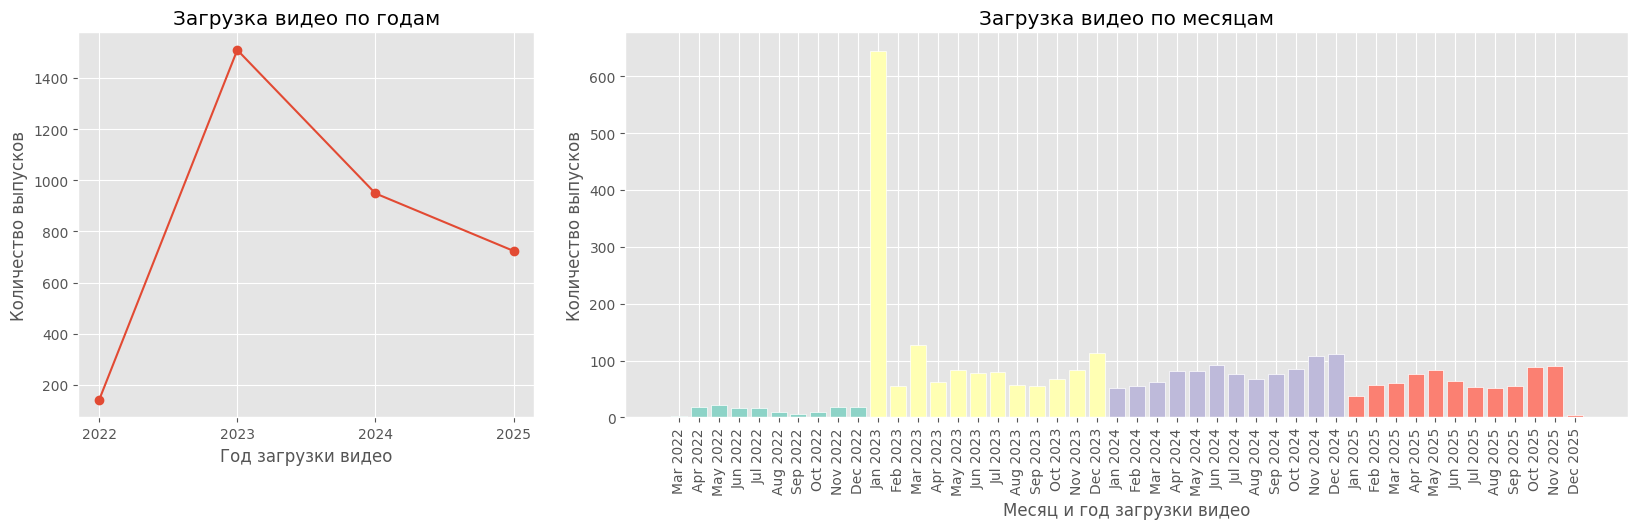

In [ ]:
#@title Выход эпизодов по годам и месяцам
from matplotlib.gridspec import GridSpec

# fig, ax = plt.subplots(figsize=(15,5))
fig=plt.figure(figsize=(20,5))
gs=GridSpec(1,3) # 2 rows, 3 columns
ax0=fig.add_subplot(gs[0,0]) # First row, first column

dates = df['date'].dropna().dt.year
labels, counts = np.unique(dates, return_counts=True)

xticks = np.arange(dates.min(), dates.max() + 1)
container = ax0.plot(labels, counts, marker='o')

ax0.set_title('Загрузка видео по годам')
ax0.set(
    xlabel='Год загрузки видео',
    ylabel='Количество выпусков',
    xticks=xticks,
)

ax1=fig.add_subplot(gs[0,1:],) # First row, first column
dates = df['date'].dropna().dt.to_period('M').dt.start_time.sort_values()

dct = dict(zip(dates.astype(str).to_list(), dates.dt.strftime('%b %Y').to_list())) # optimize
color_map = dict(zip(dates.dt.year.unique(), plt.cm.Set3.colors))

d, counts = np.unique(dates.astype(str), return_counts=True)
labels = list(map(dct.get, d))

bar_colors = list(map(color_map.get, d.astype('datetime64[Y]').astype(int) + 1970))
container = ax1.bar(x=labels, height=counts, edgecolor='white', color=bar_colors)

# ax1.bar_label(bars, fontsize=12, color='grey')

ax1.set_title('Загрузка видео по месяцам')
ax1.set(
    xlabel='Месяц и год загрузки видео',
    ylabel='Количество выпусков',
    xticks=labels,
    # rotation=90
)
ax1.tick_params("x", rotation=90);

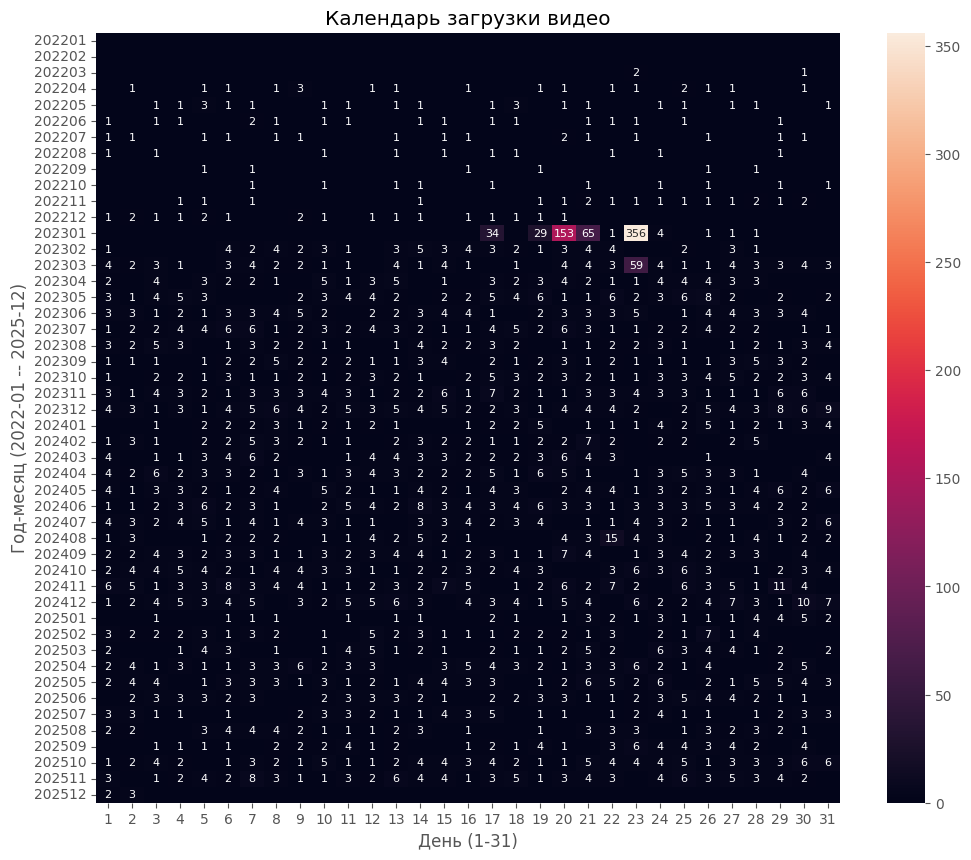

In [ ]:
# @title Календарь публикации выпусков
import seaborn as sns
# создаем календарь дней за указанный период
all_dates = []
for y in range(2022, 2026):
    for m in range(1,13):
        for d in range(1,32):
            all_dates.append(y*10000+m*100+d)

# объединяем все дни с днями, когда были загружены видео
dates_df = pd.merge(
    left=pd.DataFrame(index=all_dates),
    right=df['date'].apply(lambda d: d.year*10000+d.month*100+d.day).value_counts().sort_index(),
    how='left',
    left_index=True,
    right_index=True
).fillna(0)
dates_df['year_month'] = dates_df.index//100
dates_df['day'] = dates_df.index%100


# визуализируем "календарь": по оси x -- дни, по оси y -- год и месяц
fig, ax = plt.subplots(figsize=(12,10))
pivot = dates_df.pivot(index="year_month", columns="day", values="count")

# в аннотации оставляем только значения >0
annotations = pivot.astype(int).where(
    pivot > 0,
    ""
)

# тепловая карта
sns.heatmap(data=pivot, annot=annotations, fmt='', annot_kws={"fontsize":8}, ax=ax)

ax.set_title('Календарь загрузки видео')
ax.set(ylabel='Год-месяц (2022-01 -- 2025-12)', xlabel='День (1-31)');

В январе 2023 года наблюдается пик по количеству загруженных видео -- возможно, тогда на платформу были загружены все выпуски, которые были ранее опубликованы на YouTube.

Также по календарю виден всплеск загрузок меньшего размера -- тогда на платформу было загружено 57 выпусков шоу "Плохие песни".

### Длительность шоу

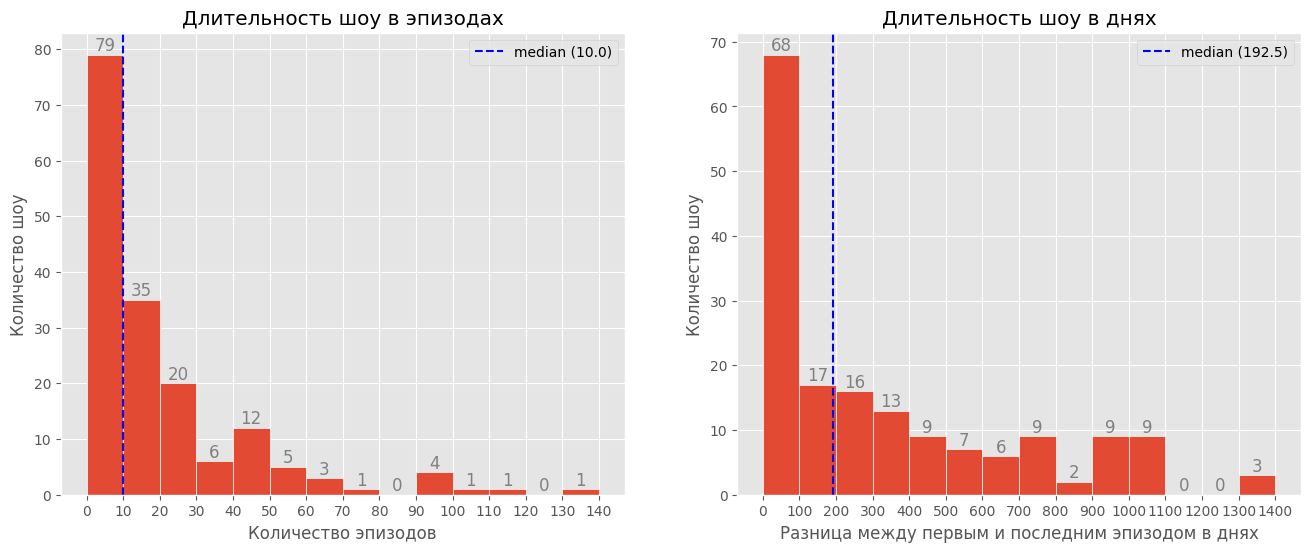

In [ ]:
# @title Длительность
# собираем информацию о времени загрузки первого и последнего выпуска для каждого шоу
aggregation_dict = {
    'date': ['min', 'max'],
    'id': 'count'
}
stats = df.groupby('show_title').agg(aggregation_dict)

# визуализируем длину шоу в эпизодах
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(8*2,6))
# fig, ax = plt.subplots(figsize=(8,6))

n_episodes = stats['id']['count']
bins = np.arange(0, n_episodes.max()+10, 10)
values, bins, bars = ax[0].hist(n_episodes, bins=bins, edgecolor='white')

ax[0].bar_label(bars, fontsize=12, color='grey')

ax[0].axvline(x=n_episodes.median(), color='b', linestyle='--', label=f'median ({round(n_episodes.median(), 2)})')

ax[0].set_title('Длительность шоу в эпизодах')
ax[0].set(xticks=bins, xlabel='Количество эпизодов', ylabel='Количество шоу')
ax[0].legend();

# визуализируем длину шоу в днях
intervals = (stats['date']['max'] - stats['date']['min']).dt.days
bins = np.arange(0, intervals.max()+100, 100)
values, bins, bars = plt.hist(intervals, bins=bins, edgecolor='white')

ax[1].bar_label(bars, fontsize=12, color='grey')

ax[1].axvline(x=intervals.median(), color='b', linestyle='--', label=f'median ({round(intervals.median(), 2)})')

ax[1].set_title('Длительность шоу в днях')
ax[1].set(xticks=bins, xlabel='Разница между первым и последним эпизодом в днях', ylabel='Количество шоу')
ax[1].legend();

### Участники проектов

In [ ]:
# Извлекаем отдельных ведущих
hosts = df['hosts_str'].dropna().str.split(',').explode().str.strip()
hosts = hosts.rename('name')
hosts.nunique()

154

In [ ]:
# Извлекаем отдельных гостей
guests = df['guests_full'].explode().str.strip()
guests = guests.rename('name')
guests.nunique()

1355

In [ ]:
print('Участвовали только в качестве гостя:', len(list(set(guests.dropna()) - set(hosts.dropna()))))

Участвовали только в качестве гостя: 1229


In [ ]:
guests_counts = guests.value_counts()
top_1perc_guests = guests_counts[guests_counts>guests_counts.quantile(0.99)]
print('Все участники, входящие в топ-1% гостей, также ведут свои шоу?', all(top_1perc_guests.index.isin(hosts.unique())))
top_1perc_guests

Все участники, входящие в топ-1% гостей, также ведут свои шоу? True


,count
name,
игорь джабраилов,121
павел дедищев,97
гурам амарян,90
антон шастун,88
зоя яровицына,87
денис дорохов,78
роман косицын,78
алексей сапрыкин,77
сергей матвиенко,74


In [ ]:
# Объединяем оба списка -- ведущих и гостей -- в сет
all_pers = list(set(hosts.dropna()) | set(guests.dropna()))
print('Количество уникальных участников:', len(all_pers))

Количество уникальных участников: 1383


In [ ]:
# Объединяем в одну последовательность, в которой считаем количество раз, человек участвовал в эпизодах в качестве ведущего или гостя
partic = pd.merge(left=hosts.value_counts().reset_index(name='count'), right=guests.value_counts().reset_index(name='count'), on='name', how='outer')
partic.columns = ['name', 'as_host', 'as_guest']
partic = partic.set_index('name')
# partic

In [ ]:
partic['sum'] = partic.sum(axis=1).astype(int)
partic['as_host'] = partic['as_host'].fillna(0).astype(int)
partic['as_guest'] = partic['as_guest'].fillna(0).astype(int)
# partic

In [ ]:
# Проверяем, что все посчиталось правильно
assert partic.loc['зоя яровицына']['sum'] == hosts.value_counts()['зоя яровицына'] + guests.value_counts()['зоя яровицына']

In [ ]:
# Топ-2% участников по количеству выпусков
top_2 = partic['sum'].quantile(0.98)
top_2_data = partic.sort_values(by='sum', ascending=False)[partic['sum']>top_2]
print('Top-2% count:', len(top_2_data))
# top_2_data['as_host_ratio'] = top_2_data['as_host'] / top_2_data['sum']
top_2_data['majority_role'] = np.where(top_2_data['as_host'] / top_2_data['sum'] > 0.5, 'host', 'guest')
top_2_data.style.background_gradient(axis=0, cmap='YlOrRd')

Top-2% count: 28


/tmp/ipykernel_6119/530421137.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  top_2_data = partic.sort_values(by='sum', ascending=False)[partic['sum']>top_2]


,as_host,as_guest,sum,majority_role
name,,,,
антон шастун,606,88,694,host
дмитрий позов,568,69,637,host
азамат мусагалиев,345,48,393,host
денис дорохов,285,78,363,host
сергей матвиенко,270,74,344,host
игорь джабраилов,204,121,325,host
арсений попов,273,38,311,host
павел дедищев,199,97,296,host
роман косицын,170,78,248,host


In [ ]:
partic.describe()

,as_host,as_guest,sum
count,1383.000000,1383.000000,1383.000000
mean,4.942878,5.228489,10.171367
std,31.809087,11.787917,40.033672
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,0.000000,1.000000,1.000000
75%,0.000000,4.000000,4.000000
max,606.000000,121.000000,694.000000


Распределение количества эпизодов, в которых появляются участники, сильно скошено вправо: медианное значение равно 1, а максимальное -- 694, при этом топ-2% по количеству выпусков вошло 28 человек, подавляющее большинство из которых участвует в выпусках в качестве ведущих. Топ-1% гостей -- ведущие других шоу.

В числе лидеров по количеству "участий" стали члены "Импровизаторов" -- Антон Шастун (694 выпуска, топ-1), Дмитрий Позов (637 выпусков, топ-2), Сергей Матвиенко (344 выпуска, топ-5) и Арсений Попов (311 выпусков, топ-7) -- вместе они ведут шоу "Громкий вопрос", "Шоу Истории", а также участвуют в разных проектах по отдельности. Также в топ-3 и топ-4 вошли Азамат Мусагалиев (393 выпуска) и Денис Дорохов (363 выпуска) соответственно -- соведущие шоу "Кстати" и собственных проектов.

In [ ]:
# антон шастун
# Контакты 	0.189855
# Громкий вопрос 	0.347826
# Шоу Истории 	0.481159
# Цитаты 	0.582609
# НЕИГРЫ 	0.672464

# дмитрий позов
# Громкий вопрос 	0.171654
# Шоу Истории 	0.316535
# НЕИГРЫ 	0.414173
# Тейбл Тайм 	0.481890
# На диване 	0.541732

# Сергей Матвиенко
# Громкий вопрос 	0.316860
# Шоу Истории 	0.584302
# Тейбл Тайм 	0.709302
# Большое шоу 	0.750000

# Арсений Попов
# Громкий вопрос 	0.350482
# Шоу Истории 	0.646302
# Тейбл Тайм 	0.784566

# Азамат Мусагалиев
# Большое шоу 	0.289003
# Кстати 	0.521739
# Я себя знаю 	0.672634
# Это логично 	0.764706

# Денис Дорохов
# Кстати 	0.252778
# Разгон 	0.383333
# Плохие выдуманные новости (ПВН) 	0.494444
# Это про меня 	0.561111

In [ ]:
# name = 'Сергей Матвиенко'.lower()
# pers_shows = df[(df['hosts_str'].fillna('').str.contains(name)) | (df['guests_full'].apply(lambda x: name in x if x else False))]['show_title'].value_counts()
# # (pers_shows / pers_shows.sum()).cumsum()
# pers_shows

In [ ]:
# вычисляем, в какой доле шоу появлялся каждый участник

# Извлекаем ведущих
hosts = pd.merge(left=df['show_title'], right=df['hosts_str'].dropna().str.split(',').explode().str.strip(), left_index=True, right_index=True, how='right').drop_duplicates()
# hosts
# Извлекаем гостей
guests = pd.merge(left=df['show_title'], right=df['guests_full'].explode().str.strip(), left_index=True, right_index=True, how='right').drop_duplicates()
# guests
parctic_shows = pd.concat([hosts.rename(columns={'hosts_str': 'name'}), guests.rename(columns={'guests_full': 'name'})], ignore_index=True).drop_duplicates()
# parctic_shows

In [ ]:
# количество шоу, в которых появился каждый участник
parctic_shows_agg = parctic_shows['name'].value_counts()
parctic_shows_agg = pd.concat([parctic_shows_agg, (parctic_shows['name'].value_counts() / df['show_title'].nunique()).rename('ratio')], axis=1)
parctic_shows_agg.describe(percentiles=[0.25,0.5,0.75,0.9,0.99])

,count,ratio
count,1383.000000,1383.000000
mean,3.536515,0.021051
std,7.022906,0.041803
min,1.000000,0.005952
25%,1.000000,0.005952
50%,1.000000,0.005952
75%,3.000000,0.017857
90%,7.000000,0.041667
99%,41.000000,0.244048
max,64.000000,0.380952


In [ ]:
# топ-20 по доле шоу, в которых они снимались
parctic_shows_agg.head(20)

,count,ratio
name,,
игорь джабраилов,64,0.380952
павел дедищев,63,0.375000
гурам амарян,55,0.327381
дмитрий позов,53,0.315476
саша ваш,52,0.309524
зоя яровицына,49,0.291667
денис дорохов,49,0.291667
расул чабдаров,48,0.285714
роман косицын,46,0.273810


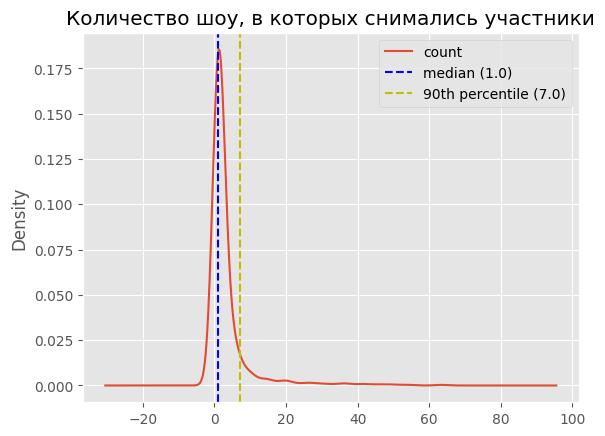

In [ ]:
parctic_shows_agg['count'].plot.kde()
plt.axvline(x=parctic_shows_agg['count'].median(), color='b', linestyle='--', label=f'median ({round(parctic_shows_agg['count'].median(), 2)})')
plt.axvline(x=parctic_shows_agg['count'].quantile(0.90), color='y', linestyle='--', label=f'90th percentile ({round(parctic_shows_agg['count'].quantile(0.90), 2)})')
plt.legend()
plt.title('Количество шоу, в которых снимались участники');

In [ ]:
# Топ-1% по количеству шоу, в которых они участвовали
top1perc_shows = parctic_shows_agg['ratio'][parctic_shows_agg['ratio']>parctic_shows_agg['ratio'].quantile(0.99)].index
# top5 = parctic_shows_ratios.head(5).index
r = parctic_shows[parctic_shows['name'].isin(top1perc_shows)]['show_title'].nunique() / df['show_title'].nunique()
print(f'Топ-1% ({len(top1perc_shows)} человек) совокупно участвовали в {r:.0%} шоу продакшена:')
print(*top1perc_shows, sep='\n')

Топ-1% (13 человек) совокупно участвовали в 83% шоу продакшена:
игорь джабраилов
павел дедищев
гурам амарян
дмитрий позов
саша ваш
зоя яровицына
денис дорохов
расул чабдаров
роман косицын
алексей сапрыкин
сергей матвиенко
антон шастун
иван абрамов


90% всех участников участвовали в 7 и менее шоу из 168. При этом топ-1% (13 человек) -- в 41 и более. Совокупно они участвовали в более, чем 80% шоу. Отдельно выделим "лидеров" Игорь Джабраилов, Павел Дедищев, Гурам Амарян, Дмитрий Позов, Саша Ваш: они появлялись в более чем в 30% всех шоу продакшена.

## Анализ социальной сети

Далее в качестве вершин выступают отдельно взятые персоналии, а в качестве ребер -- совместное появление в эпизоде, независимо от роли.

### Общее описание сети

Подготавливаем список ребер

In [ ]:
edges = df[['host_norm', 'guests_full']]
# edges

In [ ]:
# разделяем списки ведущих и гостей горизонтально, чтобы в одной строке в отдельных столбцах содержались все участники
left = edges['host_norm'].fillna('').apply(lambda x: ','.join(x)).str.split(',', expand=True)
right = edges['guests_full'].fillna('').apply(lambda x: ','.join(x)).str.split(',', expand=True)

In [ ]:
t = pd.concat([left, right], axis=1).replace(np.nan, 0)
t['combined_list'] = t.apply(lambda row: set(row.values), axis=1)
# t

In [ ]:
# составляем список парных взаимодействий -- ребер
import itertools
edges = list()
for idx, row in t.iterrows():
    edges.extend(list(itertools.combinations(list(filter(lambda x: x not in ('', 0), row['combined_list'])), 2)))

In [ ]:
from collections import Counter

interactions = Counter(edges)

In [ ]:
print('Количество парных взаимодействий (в т.ч. повторных): ', len(edges))
print('Количество уникальных пар: ', len(interactions))

Количество парных взаимодействий (в т.ч. повторных):  31701
Количество уникальных пар:  12195


Составляем список уникальных пар (ребер)

In [ ]:
import networkx as nx

In [ ]:
interactions = pd.DataFrame(interactions.items(), columns=[0, 'count'])
# interactions

In [ ]:
interactions[['left', 'right']] = interactions[0].apply(pd.Series)
interactions = interactions.drop(columns=0)
# interactions

Создаем граф

In [ ]:
G = nx.from_pandas_edgelist(
    df=interactions,
    source='left',
    target='right',
    edge_attr=['count'],
    # create_using=nx.MultiDiGraph,
)
print(G)

Graph with 1376 nodes and 11832 edges


In [ ]:
# считаем количество связанных компонент
components = list(nx.connected_components(G))
print("Количество связанных компонент:", len(components))
max_comp = max(components, key=len)
print("Размер наибольшей компоненты:", len(max_comp))
print("Другие компоненты:")
for c in components:
    if c != max_comp:
        print(c)

Количество связанных компонент: 5
Размер наибольшей компоненты: 1360
Другие компоненты:
{'илья кинопес', 'людмила светлова', 'любовь сидоркина', 'андрей бабаев'}
{'yan dilan', 'максим свобода', 'дмитрий венгеров', 'ivan'}
{'сережа омг', 'авейлу', 'seneamin', 'никита златоуст'}
{'андрей давинчи', 'николай горбунов', 'sal (poka dvoe)', 'кристина кошелева'}


Граф состоит из 1 376 вершин и 11 832 ребер. 99% вершин формируют одну компоненту связанности, и 16 человек формируют 4 отдельных компоненты (это участники проекта "Карточки", в котором нет ведущего; одна компонента -- один эпизод).

#### Распределение степеней вершин (Degree distribution)

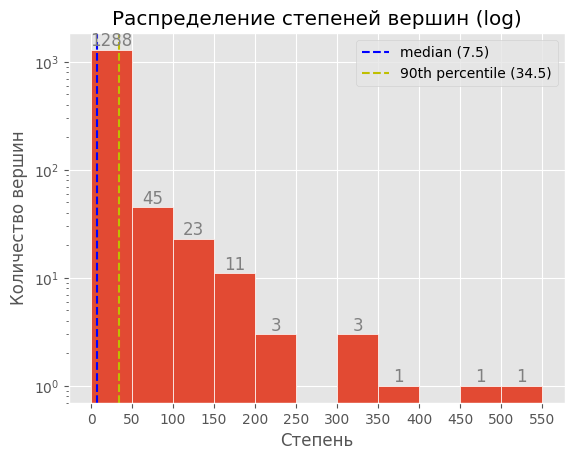

In [ ]:
degree_seq = [degree for (node, degree) in G.degree]
bins, freq = np.unique(degree_seq, return_counts=True)
bins = np.arange(0, max(degree_seq)+50, 50)
values, bins, bars = plt.hist(degree_seq, edgecolor='white', align='mid', bins=bins, log=True)

plt.axvline(x=np.median(degree_seq), color='b', linestyle='--', label=f'median ({round(np.median(degree_seq), 2)})')
plt.axvline(x=np.quantile(degree_seq, 0.90), color='y', linestyle='--', label=f'90th percentile ({round(np.quantile(degree_seq, 0.90), 2)})')

plt.xticks(bins)
plt.bar_label(bars, fontsize=12, color='grey')
plt.xlabel('Степень')
plt.ylabel('Количество вершин')
plt.title('Распределение степеней вершин (log)')
plt.legend();

In [ ]:
print('Минимальная степень вершины (взвешенная):', np.min(degree_seq))
print('Максимальная степень вершины (взвешенная):', np.max(degree_seq))

Минимальная степень вершины (взвешенная): 1
Максимальная степень вершины (взвешенная): 527


90% вершин имеет степень <40.

Проверим, является ли сеть scale-free.

> Scale-free сеть это сеть, которая имеет степенное распределение. Это значит, что большинство вершин имеют небольшое количество связей (низкую степень), а крохотная часть вершин выполняют роль хабов, имея большое количество связей.

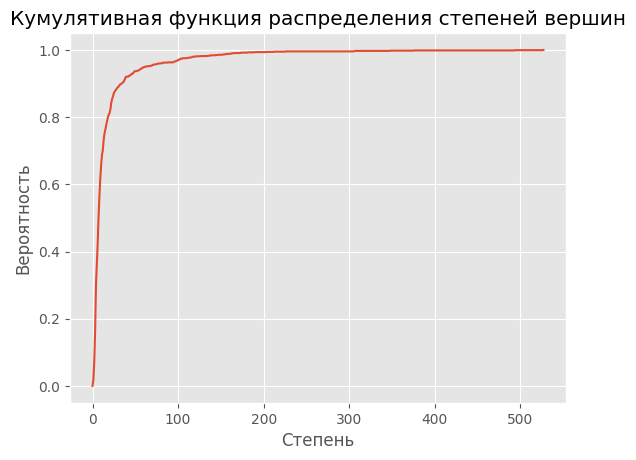

In [ ]:
def empirical_cdf(g: nx.Graph):
    """
    Вычислить кумулятивную функцию распределения (CDF) степеней вершин
    """
    hist = nx.degree_histogram(g)
    return np.cumsum(hist) / np.sum(hist)

ecdf = empirical_cdf(G)

plt.plot(ecdf)
plt.xlabel('Степень')
plt.ylabel('Вероятность')
plt.title('Кумулятивная функция распределения степеней вершин')
plt.show();

Alpha = 2.3697231384522834 r^2 = 0.9762868970154026


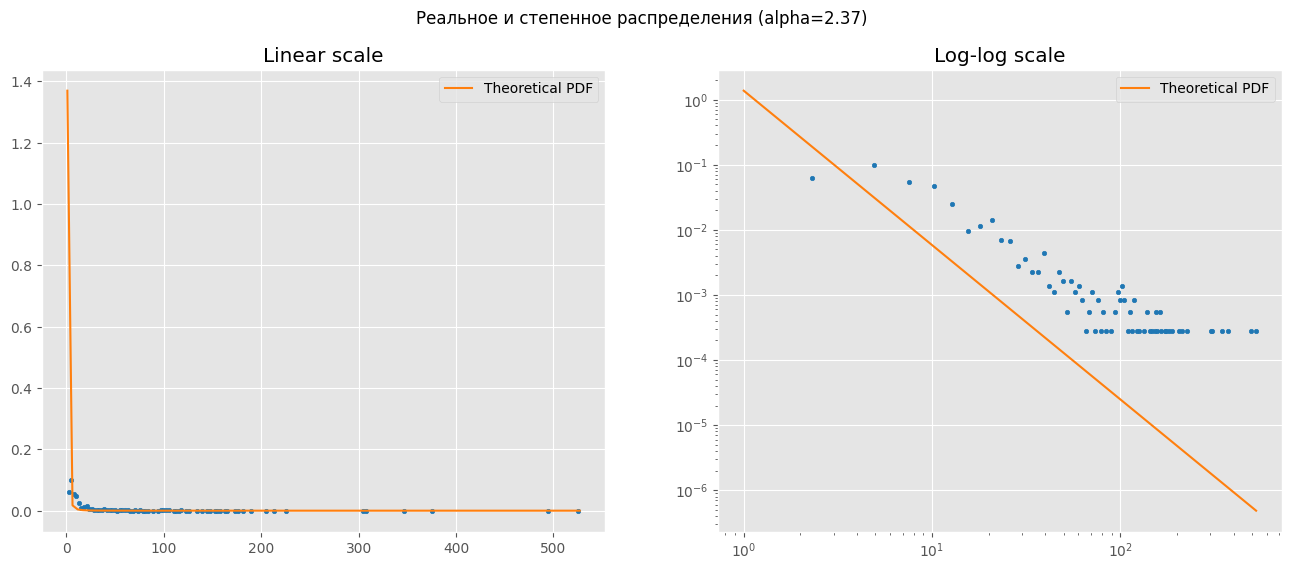

In [ ]:
# @title Сравнение со степенным распределением
# Находим alpha
from sklearn.linear_model import LinearRegression

def alpha_lin_bins(x_train, bins):
    """
    Вычислить параметр alpha для степенного распределения
    """
    hist, bin_edges = np.histogram(x_train, bins=bins, density=True)
    bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2

    idx = np.argwhere(hist > 0)

    log_centers = np.log(bin_centers[idx][:,0]).reshape(-1, 1)
    log_hist = np.log(hist[idx])

    lr = LinearRegression().fit(log_centers, log_hist)
    return -lr.coef_[0][0], lr.score(log_centers, log_hist)

alpha, r2 = alpha_lin_bins(degree_seq, bins)
print('Alpha =', alpha, 'r^2 =', r2);

# Визуализируем
def power_law_pdf(x, alpha=3.5, x_min=1):
    C = (alpha - 1) / x_min ** (1 - alpha)
    return C * x ** (-alpha)

x_min = 1

x_space = np.linspace(min(degree_seq), max(degree_seq), 100)

fig, ax = plt.subplots(1,2, figsize=(16,6))

plt.suptitle(f'Реальное и степенное распределения (alpha={round(alpha,2)})')

hist, bin_edges = np.histogram(degree_seq, bins=200, density=True)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
ax[0].scatter(bin_centers[hist > 0], hist[hist > 0], s=10, c="tab:blue")
ax[0].plot(x_space, power_law_pdf(x_space, alpha, x_min), label='Theoretical PDF', c='tab:orange')
ax[0].legend()
ax[0].set_title('Linear scale')

hist, bin_edges = np.histogram(degree_seq, bins=200, density=True)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
ax[1].scatter(bin_centers, hist, s=10, c="tab:blue")
ax[1].plot(x_space, power_law_pdf(x_space, alpha, x_min),
         label='Theoretical PDF', c='tab:orange')
ax[1].legend()
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title('Log-log scale')

plt.show();

Проверяем следование степенному распределению с помощью Log-likelihood ratio.

In [ ]:
!pip install powerlaw

In [ ]:
# проеряем на следование степенной функции
import powerlaw

fit = powerlaw.Fit(degree_seq, discrete=True)

print("Estimated alpha:", fit.alpha);

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 110/110 [00:00<00:00, 337.94it/s]

Estimated alpha: 2.0857540780289683


In [ ]:
# проверяем на следование альтернативным распределениям
R, p = fit.distribution_compare(
    "power_law",
    "lognormal",
    normalized_ratio=True
)

print("Log-likelihood ratio R:", R, f'-- more likely {"lognormal" if R<0 else "power_law"}')
print("p-value:", p)

Log-likelihood ratio R: -1.7897953293878377 -- more likely lognormal
p-value: 0.07348682031736961


In [ ]:
for alt in ["lognormal", "exponential", "stretched_exponential"]:
    R, p = fit.distribution_compare("power_law", alt, normalized_ratio=True)
    print(alt, "R:", round(R, 2), f'-- more likely {alt if R<0 else "power_law"}',"p:", p)

lognormal R: -1.79 -- more likely lognormal p: 0.07348682031736961
exponential R: 6.72 -- more likely power_law p: 1.8388313168037285e-11
stretched_exponential R: -1.68 -- more likely stretched_exponential p: 0.09287282232102616


Визуально наша сеть похожа на scale-free, т.к. степени вершин приближены  степенному распределению, однако мы не можем уверенно утверждать о такой принадлежности: статистические тесты не дали достаточного подтверждения этому (log-likelilood p-value > 0.05). Поэтому мы можем охарактеризовать нашу сеть только как hub-dominated, скошенную вправо с несколькими участниками с большим количеством связей, где все остальные участники находятся как бы на периферии.

Сравним также нашу сеть с моделями Erdos–Renyi (случайной моделью), Barabasi–Albert и Watts–Strogatz.

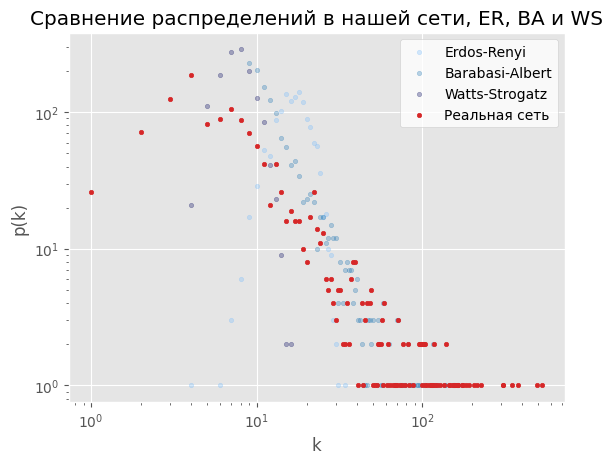

In [ ]:
# ER
def random_from_real(graph):
    """
    Случайная сеть с параметрами нашей сети n (количество степеней) и p (вероятность связи)
    """
    n = len(graph.nodes)
    mean_degree = np.mean(list(dict(graph.degree).values()))
    p = mean_degree / (n - 1) # вероятность связи
    return nx.fast_gnp_random_graph(n, p)

ER = random_from_real(G)
degree_hist_ER = np.array(nx.degree_histogram(ER))
idx = np.argwhere(degree_hist_ER > 0)
plt.scatter(idx, degree_hist_ER[idx], s=10, label='Erdos-Renyi', c='xkcd:sky blue', alpha=0.3)


# BA
def estimate_m_from_graph(G):
    """
    Сеть, сгенерированная по модели Barabasi-Albert
    """
    # https://www.math.nagoya-u.ac.jp/~richard/teaching/s2024/SML_Adam_2.pdf
    N = G.number_of_nodes()
    E = G.number_of_edges()
    m_hat = E/N
    return round(m_hat)

BA = nx.barabasi_albert_graph(n=len(G.nodes), m=estimate_m_from_graph(G)) #
degree_hist_BA = np.array(nx.degree_histogram(BA))
idx = np.argwhere(degree_hist_BA > 0)
plt.scatter(idx, degree_hist_BA[idx], s=10, label='Barabasi-Albert', c='tab:blue', alpha=0.3)


# WS
def estimate_ws_params(degrees, tol=1e-5, max_iter=100):
    """
    Сеть, сгенерированная по модели Watts-Strogatz
    """
    n = len(degrees)
    mean_deg = np.mean(degrees)
    K = mean_deg / 2
    var = np.var(degrees, ddof=1)
    p_hat = binary_search_p(degrees, K, tol, max_iter)
    return n, K, p_hat

def binary_search_p(degrees, K, tol, max_iter):
    pl, pr = 0.0, 1.0
    for _ in range(max_iter):
        p = (pl + pr) / 2
        model_var = theoretical_ws_var(degrees, K, p)
        if abs(model_var - np.var(degrees, ddof=1)) < tol:
            return p
        if model_var > np.var(degrees, ddof=1):
            pr = p
        else:
            pl = p
    return p

def theoretical_ws_var(degrees, K, p):
    n = len(degrees)
    alpha = 0.5 * p * (n - 1 - 2 * K) / n
    beta = p / n
    mean = 2 * K
    second = 2 * K * (1 - 2 * alpha + 2 * beta)
    variance = second - mean**2
    return max(variance, 0)
n, K, p = estimate_ws_params(list(dict(G.degree).values()))

WS = nx.watts_strogatz_graph(n, int(K), p)
degree_hist_WS = np.array(nx.degree_histogram(WS))
idx = np.argwhere(degree_hist_WS > 0)
plt.scatter(idx, degree_hist_WS[idx], s=10, label='Watts-Strogatz', c='xkcd:dark blue', alpha=0.3)

# наша сеть
degree_hist = np.array(nx.degree_histogram(G))
idx = np.argwhere(degree_hist > 0)
plt.scatter(idx, degree_hist[idx], s=10, label='Реальная сеть', c='tab:red')


plt.legend(facecolor="white")
plt.xlabel('k')
plt.ylabel('p(k)')
plt.title('Сравнение распределений в нашей сети, ER, BA и WS')
plt.xscale('log')
plt.yscale('log')
plt.show();

Проверим распределения с помощью теста Колмогорова-Смирнова.

In [ ]:
from scipy.stats import ks_2samp

ER_degree_seq = [degree for (node, degree) in ER.degree]
print('p-value (ER) =', round(ks_2samp(degree_seq, ER_degree_seq).pvalue,4))

BA_degree_seq = [degree for (node, degree) in BA.degree]
print('p-value (BA) =', round(ks_2samp(degree_seq, BA_degree_seq).pvalue,4))

WS_degree_seq = [degree for (node, degree) in WS.degree]
print('p-value (WS) =', round(ks_2samp(degree_seq, WS_degree_seq).pvalue,4))


p-value (ER) = 0.0
p-value (BA) = 0.0
p-value (WS) = 0.0


Тест Колмогорова-Смирнова говорит о том, что распределение степеней вершин в нашей сети не сгенерировано ни одной из моделей (на уровне значимости 0.05). Однако это не значит, что ей не свойственно предпочтительное присоединение (чем больше у вершины связей, тем больше вероятность появления новых) или она имеет small-world структуры (большинство вершин могут быть достигнуты из любой другой вершины за малое количество шагов). Проверим это ниже.

#### Среднее расстояние (Average distance) и коэффициент кластеризации (Clustering coefficient)

Поскольку в сети есть вершины, между которыми нет ни прямой, ни опосредованной связи до некоторых других, для вычисления статистик выберем наибольшую компоненту связанности.

In [ ]:
def select_largest_component(g: nx.Graph) -> nx.Graph:
    """
    Вернуть наибольший подграф
    """
    nodes = max(nx.connected_components(g), key=len)
    return g.subgraph(nodes)

G_sub = select_largest_component(G)
print('Вершин в подграфе:', len(G_sub.nodes()))
print('Ребер в подграфе:', len(G_sub.edges()))

Вершин в подграфе: 1360
Ребер в подграфе: 11808


In [ ]:
c = {}
l = {}

l_ = nx.average_shortest_path_length(G_sub)
c_ = nx.average_clustering(G_sub)

c['Реальная сеть'] = c_
l['Реальная сеть'] = l_

print('Радиус: ', nx.radius(G_sub))
print('Диаметр: ', nx.diameter(G_sub))
print('Средняя длина кратчайшего пути: ', l_)
print('Срединй коэффициент кластеризации: ', c_)

Радиус:  3
Диаметр:  6
Средняя длина кратчайшего пути:  2.6447030688655153
Срединй коэффициент кластеризации:  0.7784659210430994


Сравним с коэффициентами кластеризации и длинами кратчайшего пути моделей ER, BA, WS

In [ ]:
for m_ in ['ER', 'BA', 'WS']:
    m = eval(m_)
    # print('Радиус: ', nx.radius(m))
    # print('Диаметр: ', nx.diameter(m))
    c_ = nx.average_clustering(m)
    l_ = nx.average_shortest_path_length(m)

    c[m_] = c_
    l[m_] = l_
    print(f'Средняя длина кратчайшего пути в {m_}: ', l_)
    print(f'Срединй коэффициент кластеризации в {m_}: ', c_)
    print()

Средняя длина кратчайшего пути в ER:  2.81866650552186
Срединй коэффициент кластеризации в ER:  0.012778473027273534

Средняя длина кратчайшего пути в BA:  2.6783401236786393
Срединй коэффициент кластеризации в BA:  0.04798587159725889

Средняя длина кратчайшего пути в WS:  3.7267864014986465
Срединй коэффициент кластеризации в WS:  0.006942192531712182



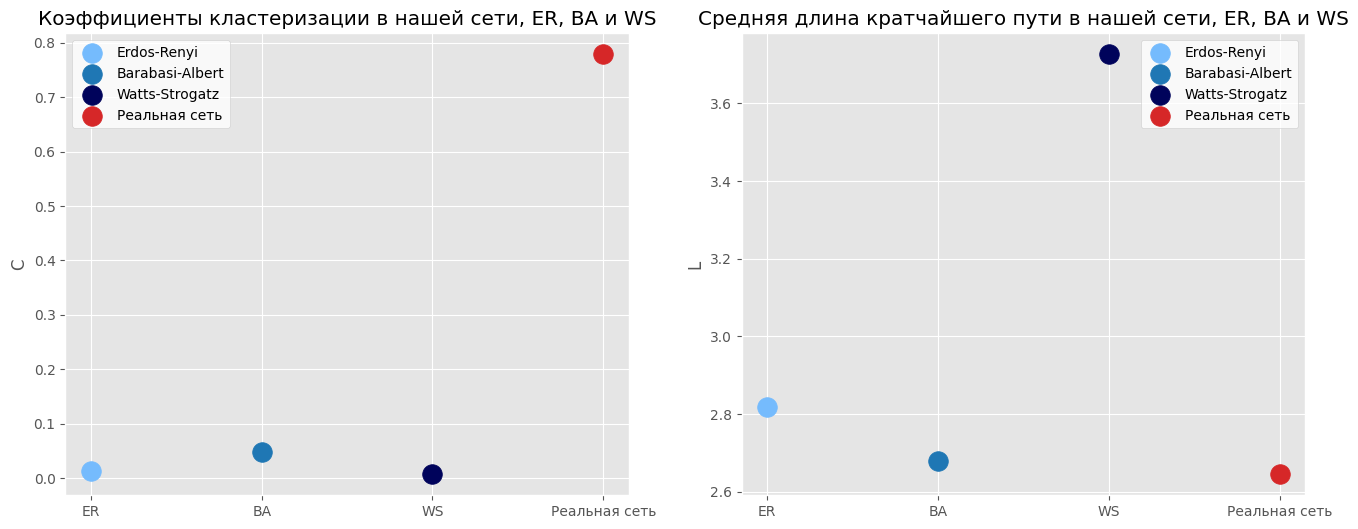

In [ ]:
fix, ax = plt.subplots(1,2, figsize=(16,6))

ax[0].scatter('ER', c['ER'], s=200, label='Erdos-Renyi', c='xkcd:sky blue')
ax[0].scatter('BA', c['BA'], s=200, label='Barabasi-Albert', c='tab:blue')
ax[0].scatter('WS', c['WS'], s=200, label='Watts-Strogatz', c='xkcd:dark blue')
ax[0].scatter('Реальная сеть', c['Реальная сеть'], s=200, c='tab:red', label='Реальная сеть')

ax[0].legend(facecolor="white")
# plt.xlabel('k')
ax[0].set_ylabel('C')
ax[0].set_title('Коэффициенты кластеризации в нашей сети, ER, BA и WS')



ax[1].scatter('ER', l['ER'], s=200, label='Erdos-Renyi', c='xkcd:sky blue')
ax[1].scatter('BA', l['BA'], s=200, label='Barabasi-Albert', c='tab:blue')
ax[1].scatter('WS', l['WS'], s=200, label='Watts-Strogatz', c='xkcd:dark blue')
ax[1].scatter('Реальная сеть', l['Реальная сеть'], s=200, c='tab:red', label='Реальная сеть')

ax[1].legend(facecolor="white")
# plt.xlabel('k')
ax[1].set_ylabel('L')
ax[1].set_title('Средняя длина кратчайшего пути в нашей сети, ER, BA и WS')


plt.show();

Нашу сеть можно назвать small-world, поскольку ей свойственна высокая степень кластеризации и короткие расстояния между вершинами, вероятнее всего, благодаря хабам.
Высокий коэффициент кластеризации говорит о наличии небольших групп, которые часто появляются вместе: если A снимался в одном выпуске вместе с B и C, то B и C также снимаются вместе.

#### Определение хабов

Хабы выполняют роль связующего звена и имеют гораздо больше соединений, чем "средняя" вершина в сети. Хабы мы определим как вершины, которые имеют аномально высокие степени -- выбросы, находящиеся на расстоянии 5 стандартных отклонений от 75-го перцентиля.

In [ ]:
degrees = pd.Series(dict(G.degree(weight='count'))).rename('degree').sort_values(ascending=False)
# degrees
hub_degree_threshold = get_upper_iqr_threshold(degrees, coeff=5)
print('Минимально возможная степень хаба:', hub_degree_threshold)

Минимально возможная степень хаба: 100.0


In [ ]:
hubs = degrees[degrees>=hub_degree_threshold]
print('Количество хабов:', len(hubs))
print('Хабы (со указанием степени вершины):')
print(hubs)

Количество хабов: 122
Хабы (со указанием степени вершины):
азамат мусагалиев    1748
дмитрий позов        1251
денис дорохов        1079
антон шастун          936
игорь джабраилов      821
                     ... 
чермен качмазов       106
артемий лебедев       106
татьяна клац          102
анастасия ли          101
мария маркова         100
Name: degree, Length: 122, dtype: int64


#### Визуализация

In [ ]:
# чтобы облегчить визуализацию, оставим только вершины, входящие в 75-й перцентиль по степени вершины
threshold = degrees.quantile(0.75)  # for example

keep_nodes = degrees[degrees >= threshold].index
G_vis = G.subgraph(keep_nodes)

print(f"Изначальное количество вершин: {G.number_of_nodes()}")
print(f"Количество вершин в сокращенном графе: {G_vis.number_of_nodes()}")
print(f"Минимальная степень вершины: {threshold}")

pos = nx.kamada_kawai_layout(G_vis, scale=5)

Изначальное количество вершин: 1376
Количество вершин в сокращенном графе: 347
Минимальная степень вершины: 20.0


In [ ]:
# на визуализации будут отражены и выделены цветом только имена "хабов"
labels = {}
color_map = []
for node in G_vis.nodes():
    if node in hubs:
        labels[node] = node
        color_map.append('orange')
    else:
        color_map.append('skyblue')

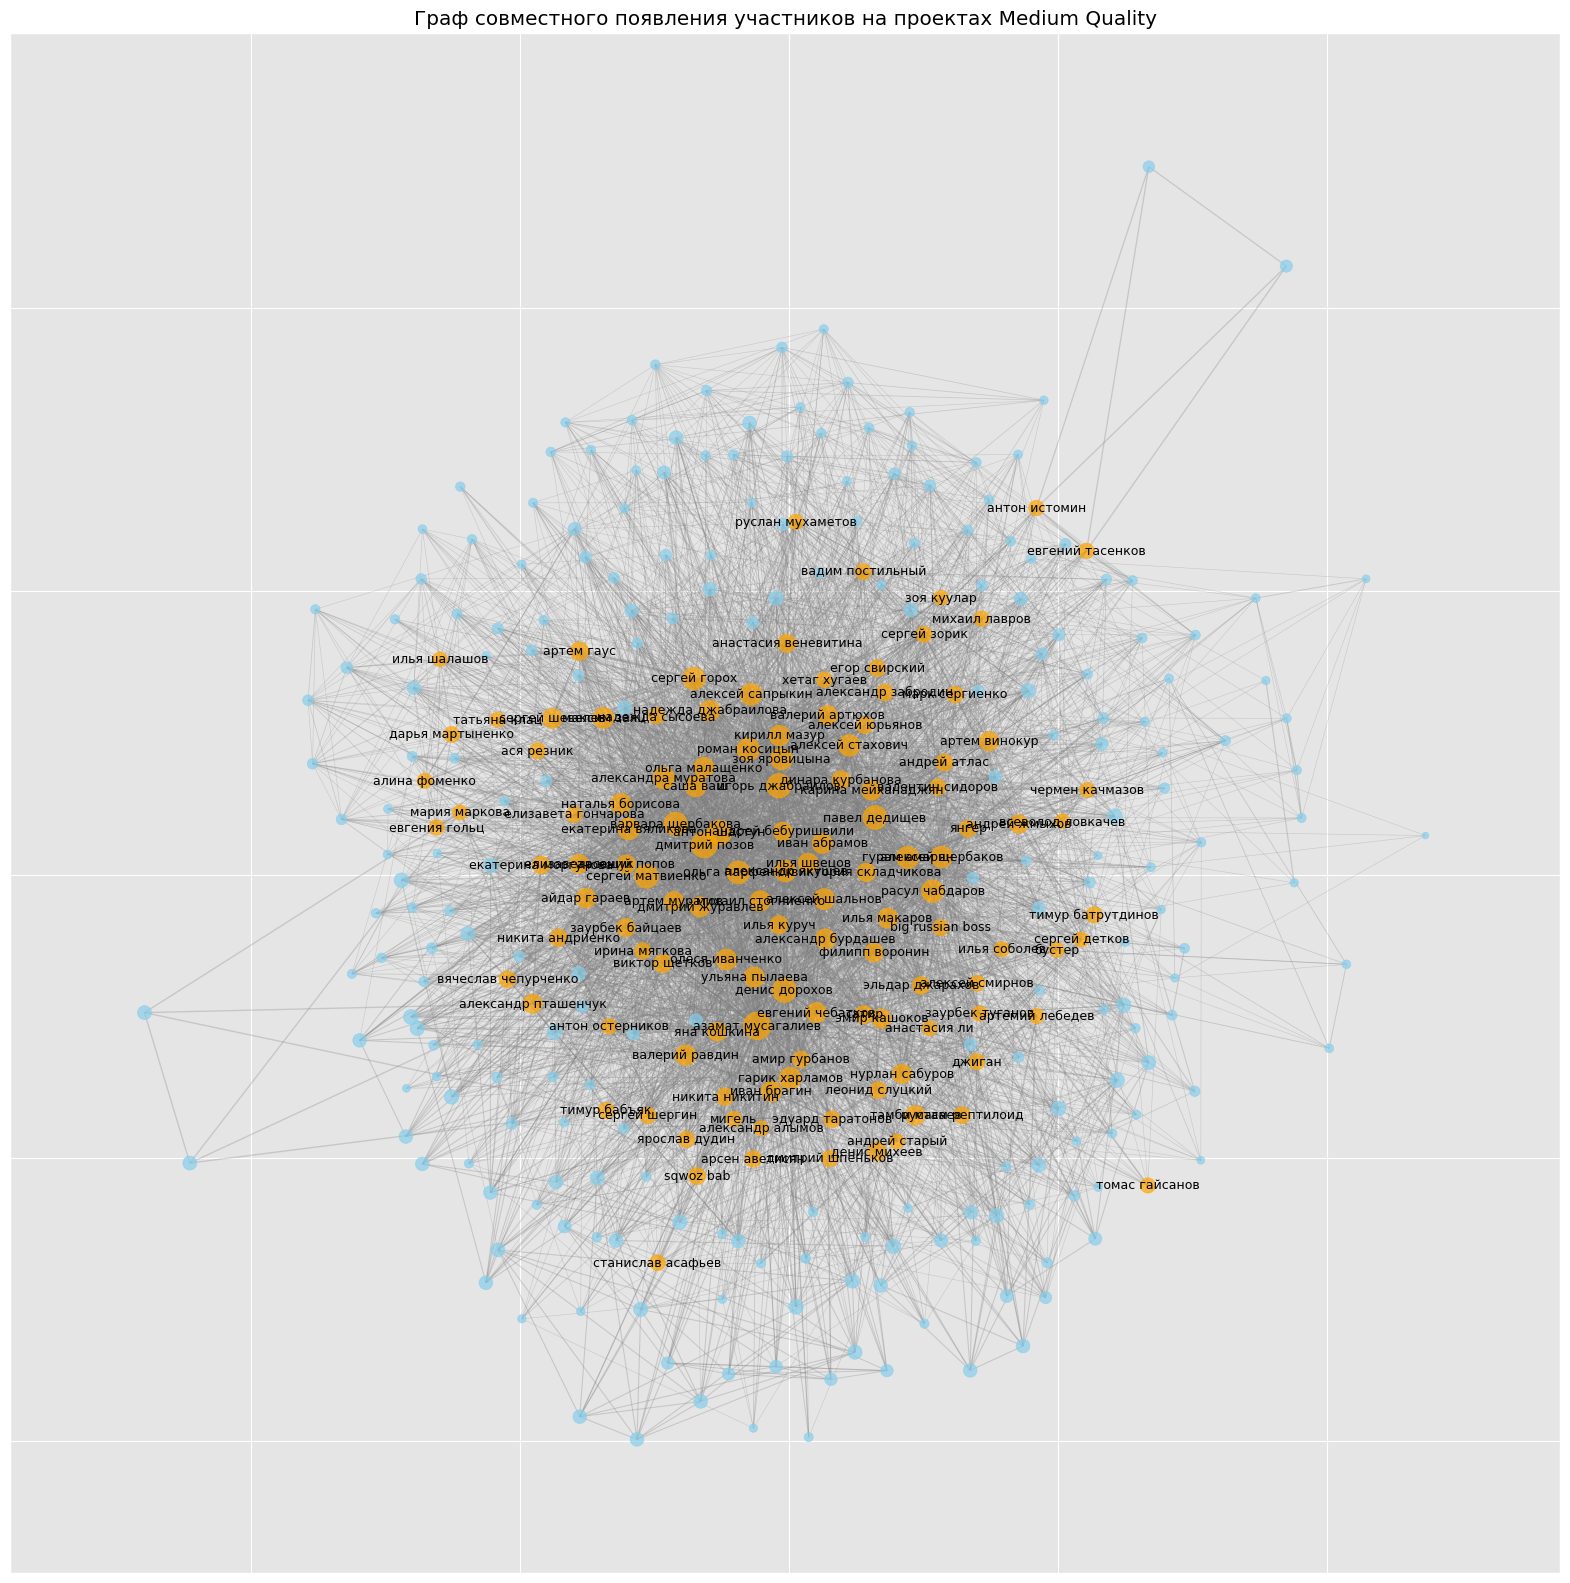

In [ ]:
# pos = nx.forceatlas2_layout(G_2025, scaling_ratio=200)

plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_vis, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_vis.degree(weight='count')).values()], alpha=0.7, node_color=color_map)
nx.draw_networkx_edges(G_vis, pos, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_vis, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_vis, pos,labels,font_size=9,font_color='black')

plt.title("Граф совместного появления участников на проектах Medium Quality")
plt.show();

Так как вершин и ребер слишком много, визуализировать граф статично на плоскости недостаточно. Создадим интерактивную сеть в другой конфигурации с помощью библиотеки ploty.

#### Визуализация в plotly

In [ ]:
import plotly.graph_objects as go


edge_x = []
edge_y = []
for edge in G_vis.edges():
    x0, y0 = pos[edge[0]]
    x1, y1 = pos[edge[1]]
    edge_x.append(x0)
    edge_x.append(x1)
    edge_x.append(None)
    edge_y.append(y0)
    edge_y.append(y1)
    edge_y.append(None)

edge_trace = go.Scatter(
    x=edge_x, y=edge_y,
    line=dict(width=1, color='rgba(0.5, 0.5, 0.5, 0.3)'),
    hoverinfo='none',
    mode='lines')

node_x = []
node_y = []
colors = []

for node in G_vis.nodes():
    x, y = pos[node]
    node_x.append(x)
    node_y.append(y)
    if node in hubs:
        colors.append('orange')
    else:
        colors.append('skyblue')

node_trace = go.Scatter(
    x=node_x, y=node_y,
    mode='markers',
    hoverinfo='text',
    marker=dict(
        # showscale=True,
        # colorscale='YlGnBu',
        # reversescale=True,
        color=colors,
        size=5,
        # colorbar=dict(
        #     thickness=15,
        #     title=dict(
        #       text='Node Connections',
        #       side='right'
        #     ),
        #     xanchor='left',
        # ),
        line_width=2))

In [ ]:
node_adjacencies = []
node_text = []
# for node, adjacencies in enumerate(G.adjacency()):
#     node_adjacencies.append(np.log(len(adjacencies[1])))
#     # node_text.append('# of connections: '+str(len(adjacencies[1])))
#     node_text.append(adjacencies[0])

for p, d in dict(G_vis.degree(weight='count')).items():
    node_adjacencies.append(np.log(d)**2)
    node_text.append(p)

# node_trace.marker.color = node_adjacencies
node_trace.text = node_text
node_trace.marker.size = node_adjacencies

In [ ]:
import plotly.graph_objects as go

fig = go.Figure(data=[edge_trace, node_trace],
             layout=go.Layout(
                title=dict(
                    text="Граф совместного участников на проектах Medium Quality",
                    font=dict(
                        size=16
                    ),
                ),
                height=1200,
                width=1600,
                showlegend=False,
                hovermode='closest',
                margin=dict(b=20,l=5,r=5,t=40),
                annotations=[ dict(
                    showarrow=True,
                    xref="paper", yref="paper",
                    x=0.005, y=-0.002 ) ],
                xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
                yaxis=dict(showgrid=False, zeroline=False, showticklabels=False))
                )
fig.show();

In [ ]:
fig.write_html("plotly_network.html")

### Структурный анализ

#### Центральность (Centrality measures)

Рассмотрим меры центральности нашей сети и выделим участников с наибольшими значениями мер

In [ ]:
# вычисляем меры центральности
degrees_c = pd.DataFrame(dict(nx.degree_centrality(G)).items(), columns=('name', 'degree')).set_index('name')

betweenness_c = pd.DataFrame(dict(nx.betweenness_centrality(G, weight="count")).items(), columns=('name', 'betweenness')).set_index('name')

closeness_c = pd.DataFrame(dict(nx.closeness_centrality(G)).items(), columns=('name', 'closeness')).set_index('name')

eig_c = pd.DataFrame(dict(nx.eigenvector_centrality(G, weight="count")).items(), columns=('name', 'eigenvector')).set_index('name')

centralities = pd.concat([degrees_c, betweenness_c, closeness_c, eig_c],axis=1)
print(centralities.head())

                      degree  betweenness  closeness  eigenvector
name                                                             
антон шастун        0.222545     0.055045   0.540083     0.144770
сергей матвиенко    0.138182     0.024304   0.510523     0.479164
александр забродин  0.044364     0.002562   0.467195     0.064924
сергей горох        0.077091     0.007864   0.491470     0.211185
валерий равдин      0.055273     0.003353   0.479709     0.048547


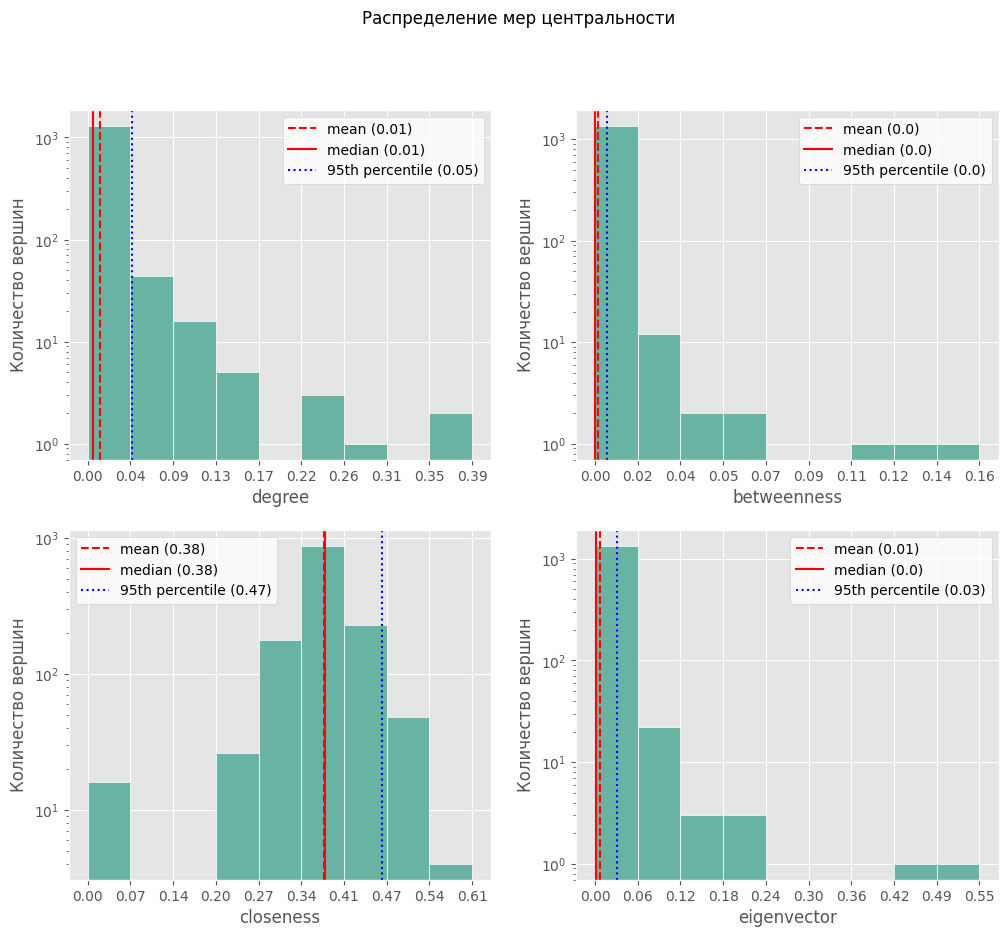

In [ ]:
# визуализируем распределения мер центральности
import matplotlib.ticker as ticker
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()

for i, column in enumerate(centralities.columns):
    col = centralities[column]
    bins = np.linspace(0, col.max()+0.01, 10)
    # bins = np.arange(0, col.max()+0.01, 0.01)
    axes[i].hist(col, bins=bins, edgecolor='white', color='#69b3a2')

    axes[i].axvline(x=col.mean(), color='r', linestyle='--', label=f'mean ({round(col.mean(), 2)})')
    axes[i].axvline(x=col.median(), color='r', linestyle='-', label=f'median ({round(col.median(), 2)})')
    axes[i].axvline(x=col.quantile(0.95), color='b', linestyle=':', label=f'95th percentile ({round(col.quantile(0.95), 2)})')

    # axes[i].set_title(f'{column}')

    axes[i].set(xticks=bins)
    axes[i].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:.2f}'))
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Количество вершин')
    axes[i].set_yscale('log')
    axes[i].legend(facecolor='white')

# plt.tight_layout()
plt.suptitle('Распределение мер центральности')
plt.show();


Околонулевые значения 95-го перцентиля для degree, betweenness и eigenvector подтверждают вывод о том, что сеть hub-dominated, то есть существует узкий круг участников, которые снимаются в большом количестве шоу и соединяют бОльшую часть сети. Среднее значение closeness, равное 0.38 также подтверждает другой вывод о том, что типичный участник связан с любым другим участником через небольшое количество вершин.

Далее рассмотрим участников, которые имеют наибольшие значения мер центральности.

In [ ]:
print('Высокие меры центральности:')
centr_measures = ['degree', 'betweenness', 'closeness', 'eigenvector']
outlier_coeffs = [5,5,3,5]
for m, c in zip(centr_measures, outlier_coeffs):
    threshold = get_upper_iqr_threshold(centralities[m], coeff=c)
    print()
    print(m, f'(median={round(centralities[m].median(), 2)}), threshold={round(threshold,4)} (0.75th percentile + {c})')
    print(centralities[centralities[m]>threshold][m].sort_values(ascending=False))

Высокие меры центральности:

degree (median=0.01), threshold=0.032
name
азамат мусагалиев            0.383273
денис дорохов                0.359273
дмитрий позов                0.273455
гарик харламов               0.253091
павел дедищев                0.223273
                               ...   
алексей шамутило             0.033455
тимур батрутдинов            0.033455
елизавета варвара аранова    0.032727
алексей смирнов              0.032727
ася резник                   0.032727
Name: degree, Length: 104, dtype: float64

betweenness (median=0.0), threshold=0.0013
name
азамат мусагалиев     0.148079
денис дорохов         0.131890
дмитрий позов         0.110030
павел дедищев         0.068857
антон шастун          0.055045
                        ...   
евгения гришечкина    0.001393
lone                  0.001384
дмитрий шнякин        0.001377
юлианна караулова     0.001376
софья шац             0.001335
Name: betweenness, Length: 172, dtype: float64

closeness (median=0.38), thres

`degree` -- количество прямых связей.

Большая часть персоналий, определенных как хабы, также имеют аномально высокие значения degree (дальше трех стандартных отклонений от 75-го перцентиля). Это популярные и активные участники, которые снимаются в большом количестве проектов и/или ведут шоу, которые подразумевают разнообразие приглашенных гостей.

`betweenness` -- чем выше значение, тем чаще через вершину пролегает кратчайший путь между другими вершинами.

Такие участники выполняют роль "мостов", соединяя группы других участников. Это могут быть как ведущие популярных шоу, в которых участвовало большое количество гостей, так и гости, которые посетили шоу, где ведущие являются хабами.

`closeness` -- как быстро вершина может достигнуть любой другой вершины.

Аномально высокое значение этой меры имеют 6 человек -- ведущие продолжительных шоу с участием гостей: "Кстати", "Большое шоу", "Контакты", "Громкий вопрос", "БЫЛОСЛОВО" и др.

`eigenvector` -- количество связей с другими вершинами, имеющими много связей.


degree--degree rho = 0.9999999999999999 p-value = 0.0
degree--betweenness rho = 0.8265201394781838 p-value = 0.0
degree--closeness rho = 0.7745707757217036 p-value = 1.2266750420157142e-275
degree--eigenvector rho = 0.7746551823020346 p-value = 9.798024997965983e-276


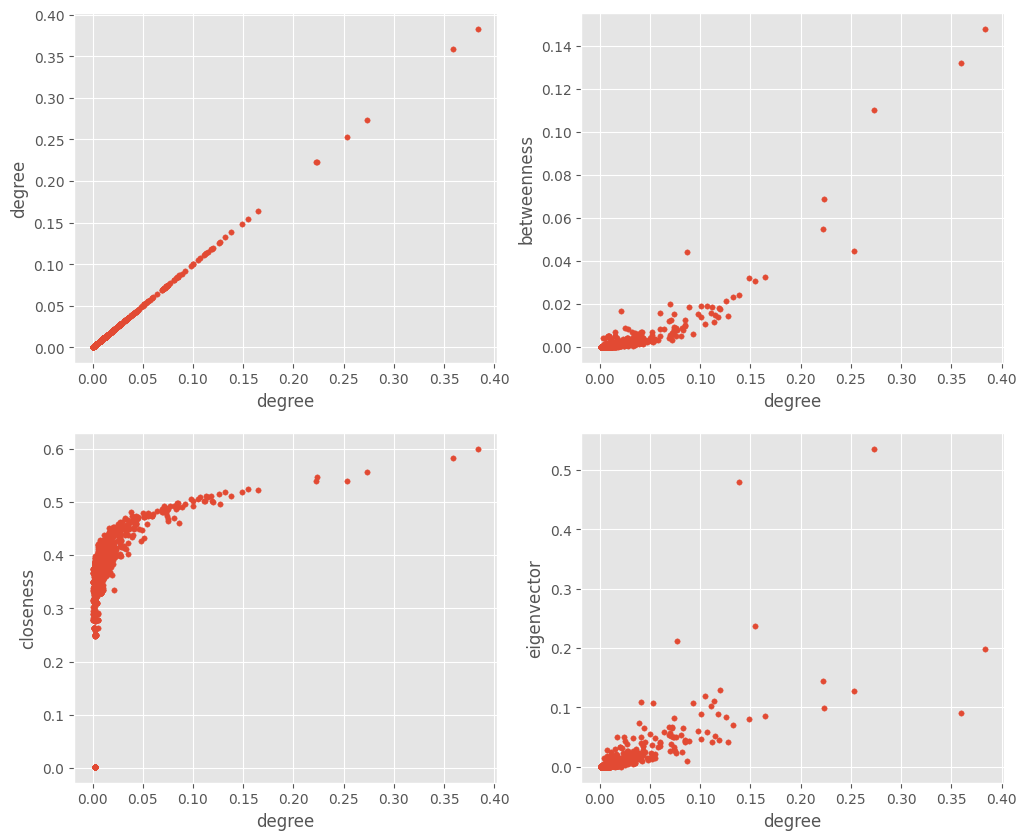

In [ ]:
from scipy import stats
centr_measures = ['degree', 'betweenness', 'closeness', 'eigenvector']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()
for i, m in enumerate(centr_measures):

    s = centralities[m]
    axes[i].scatter(x=centralities['degree'], y=s, s=15, linewidths=0.3)
    axes[i].set(xlabel='degree', ylabel=m)

    res = stats.spearmanr(centralities['degree'], s)
    print(f'{'degree'}--{m}', 'rho =', res.statistic, 'p-value =', res.pvalue)


# plt.legend(facecolor="white")
# plt.grid()
# plt.title('Меры центральности и топ-10 участников с наибольшими значениями мер');
# plt.xticks(rotation=90);

Из графика распределений мер центральности и значений корреляции мы видим, что чем больше степень вершины, тем выше любая другая мера центральности. Это в очередной раз говорит о том, что те немногочисленные персоналии, которые имеют наибольшее количество связей, выполняют "общих" хабов, которые связывают другие вершины сети, делая ее более "однородной" -- через такие хабы осуществляется взаимодействие.


Азамат Мусагалиев и Дмитрий Дорохов имеют аномально высокие меры центральности. Они являются крупнейшими хабами, появлялись в эпизодах с наибольшим количеством других участников

#### Ассортативность (Degree mixing pattern)

In [ ]:
r = nx.degree_assortativity_coefficient(G, weight='count')

print(f"Ассортативность по степени вершин: {r:3.1f}")

Ассортативность по степени вершин: -0.2


Значение ассортативности близко к нулю, что означает слабую зависимость вероятности присоединения от степени вершины, или небольшую склонность вершин с высокой степенью присоединяться к вершиной с низкой степенью.

### Определение сообществ

Рассмотрим сообщества, определенные на основе совместных появлений в выпусках, опубликованных в 2025 году

In [ ]:
# создаем граф для 2025 года
edges_2025 = df[df['date']>='2025-01-01'][['host_norm', 'guests_full']]
# разделяем списки ведущих и гостей горизонтально, чтобы в одной строке в отдельных столбцах содержались все участники
left_2025 = edges_2025['host_norm'].fillna('').apply(lambda x: ','.join(x)).str.split(',', expand=True)
right_2025 = edges_2025['guests_full'].fillna('').apply(lambda x: ','.join(x)).str.split(',', expand=True)
t_2025 = pd.concat([left_2025, right_2025], axis=1).replace(np.nan, 0)
t_2025['combined_list'] = t_2025.apply(lambda row: set(row.values), axis=1)
edges_2025 = list()
for idx, row in t_2025.iterrows():
    edges_2025.extend(list(itertools.combinations(list(filter(lambda x: x not in ('', 0), row['combined_list'])), 2)))
interactions_2025 = Counter(edges_2025)

# Составляем список уникальных пар (ребер)
interactions_2025 = pd.DataFrame(interactions_2025.items(), columns=[0, 'count'])
# interactions_2025
interactions_2025[['left', 'right']] = interactions_2025[0].apply(pd.Series)
interactions_2025 = interactions_2025.drop(columns=0)
# interactions_2025
# Создаем граф
G_2025 = nx.from_pandas_edgelist(
    df=interactions_2025,
    source='left',
    target='right',
    edge_attr=['count'],
    # create_using=nx.MultiDiGraph,
)
print(G_2025)

Graph with 577 nodes and 3692 edges


In [ ]:
def visualize_community(com_number, com_set, title=None, annotated_degree_min_threshold=0, dims=(20,20)):
    """
    Визуализировать вершины и связи внутри конкретного сообщества. Добавить подписи для топ-20 в сообществе по степени вершины, покрасить красным хабы
    """
    cur_comm = com_set[com_number]

    # edgelist_sub = [e for e in edges if e[0] in cur_comm or e[1] in cur_comm] # включаем членов сообщества + всех, кто снимался с ними хотя бы раз
    edgelist_sub = [e for e in edges if e[0] in cur_comm and e[1] in cur_comm] # включаем только членов сообщества

    G_sub = nx.from_edgelist(edgelist_sub)
    print(G_sub)

    # 3. Process the results for visualization
    # Create a dictionary to map each node to its community ID
    node2color = {}
    for pair in G_sub.edges:
        for node in pair:
            if node in hubs:
                node2color[node] = 'red'
            else:
                node2color[node] = 'blue'

    # Get a list of community IDs in the order of the nodes
    node_colors = [node2color[node] for node in G_sub.nodes()]

    # pos = nx.kamada_kawai_layout(G_sub)
    pos = nx.forceatlas2_layout(G_sub, scaling_ratio=100)

    # top_20 = list(dict(sorted(dict(G_sub.degree).items(), key=lambda x: x[1], reverse=True)[:20]).keys())

    labels = {}
    for node in G_sub.nodes():
        if node in cur_comm and node in hubs:
            labels[node] = node


    plt.figure(figsize=dims)

    nx.draw_networkx_nodes(G_sub, pos, node_size=[x*10 + 20 for x in dict(G_sub.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
    nx.draw_networkx_edges(G_sub, pos, arrows=True, edge_color='gray', alpha=0.3) #  width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_sub, 'count').values())]
    nx.draw_networkx_labels(G_sub, pos,labels,font_size=9,font_color='black')

    if not title:
        title = f"Сообщество {com_number}"
    plt.title(title)
    # plt.legend()
    plt.show();

#### Clauset-Newman-Moore Greedy Modularity Maximization

Модулярность сравнивает количество ребер внутри сообществ с тем, что ожидается в случайной сети с тем же распределением степеней.

In [ ]:
comm_greedy = list(nx.algorithms.community.greedy_modularity_communities(G_2025))
print('Количество сообществ по Clauset-Newman-Moore Greedy Modularity Maximization:', len(comm_greedy))
modularity_score = nx.community.modularity(G_2025, comm_greedy, weight="weight")
print('Модулярность по Clauset-Newman-Moore Greedy Modularity Maximization', round(modularity_score,2))

Количество сообществ по Clauset-Newman-Moore Greedy Modularity Maximization: 18
Модулярность по Clauset-Newman-Moore Greedy Modularity Maximization 0.41


Значение модулярности 0.41 говорит о том, что внутри сообщества наблюдается больше связей, чем ожидается в случайном графе; существуют сообщества, но при этом сеть не фрагментирована.

Визуализируем полную сеть, выделяя цветом отдельные сообщества


In [ ]:
import matplotlib as mpl

In [ ]:
degrees = pd.Series(dict(G_2025.degree()))
threshold = degrees.quantile(0.75)  # for example

keep_nodes = degrees[degrees >= threshold].index
G_vis = G_2025.subgraph(keep_nodes)

print(f"Изначальное количество вершин: {G_2025.number_of_nodes()}")
print(f"Количество вершин в сокращенном графе: {G_vis.number_of_nodes()}")
print(f"Минимальная степень вершины: {threshold}")

pos = nx.kamada_kawai_layout(G_vis, scale=5)

Изначальное количество вершин: 577
Количество вершин в сокращенном графе: 152
Минимальная степень вершины: 11.0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



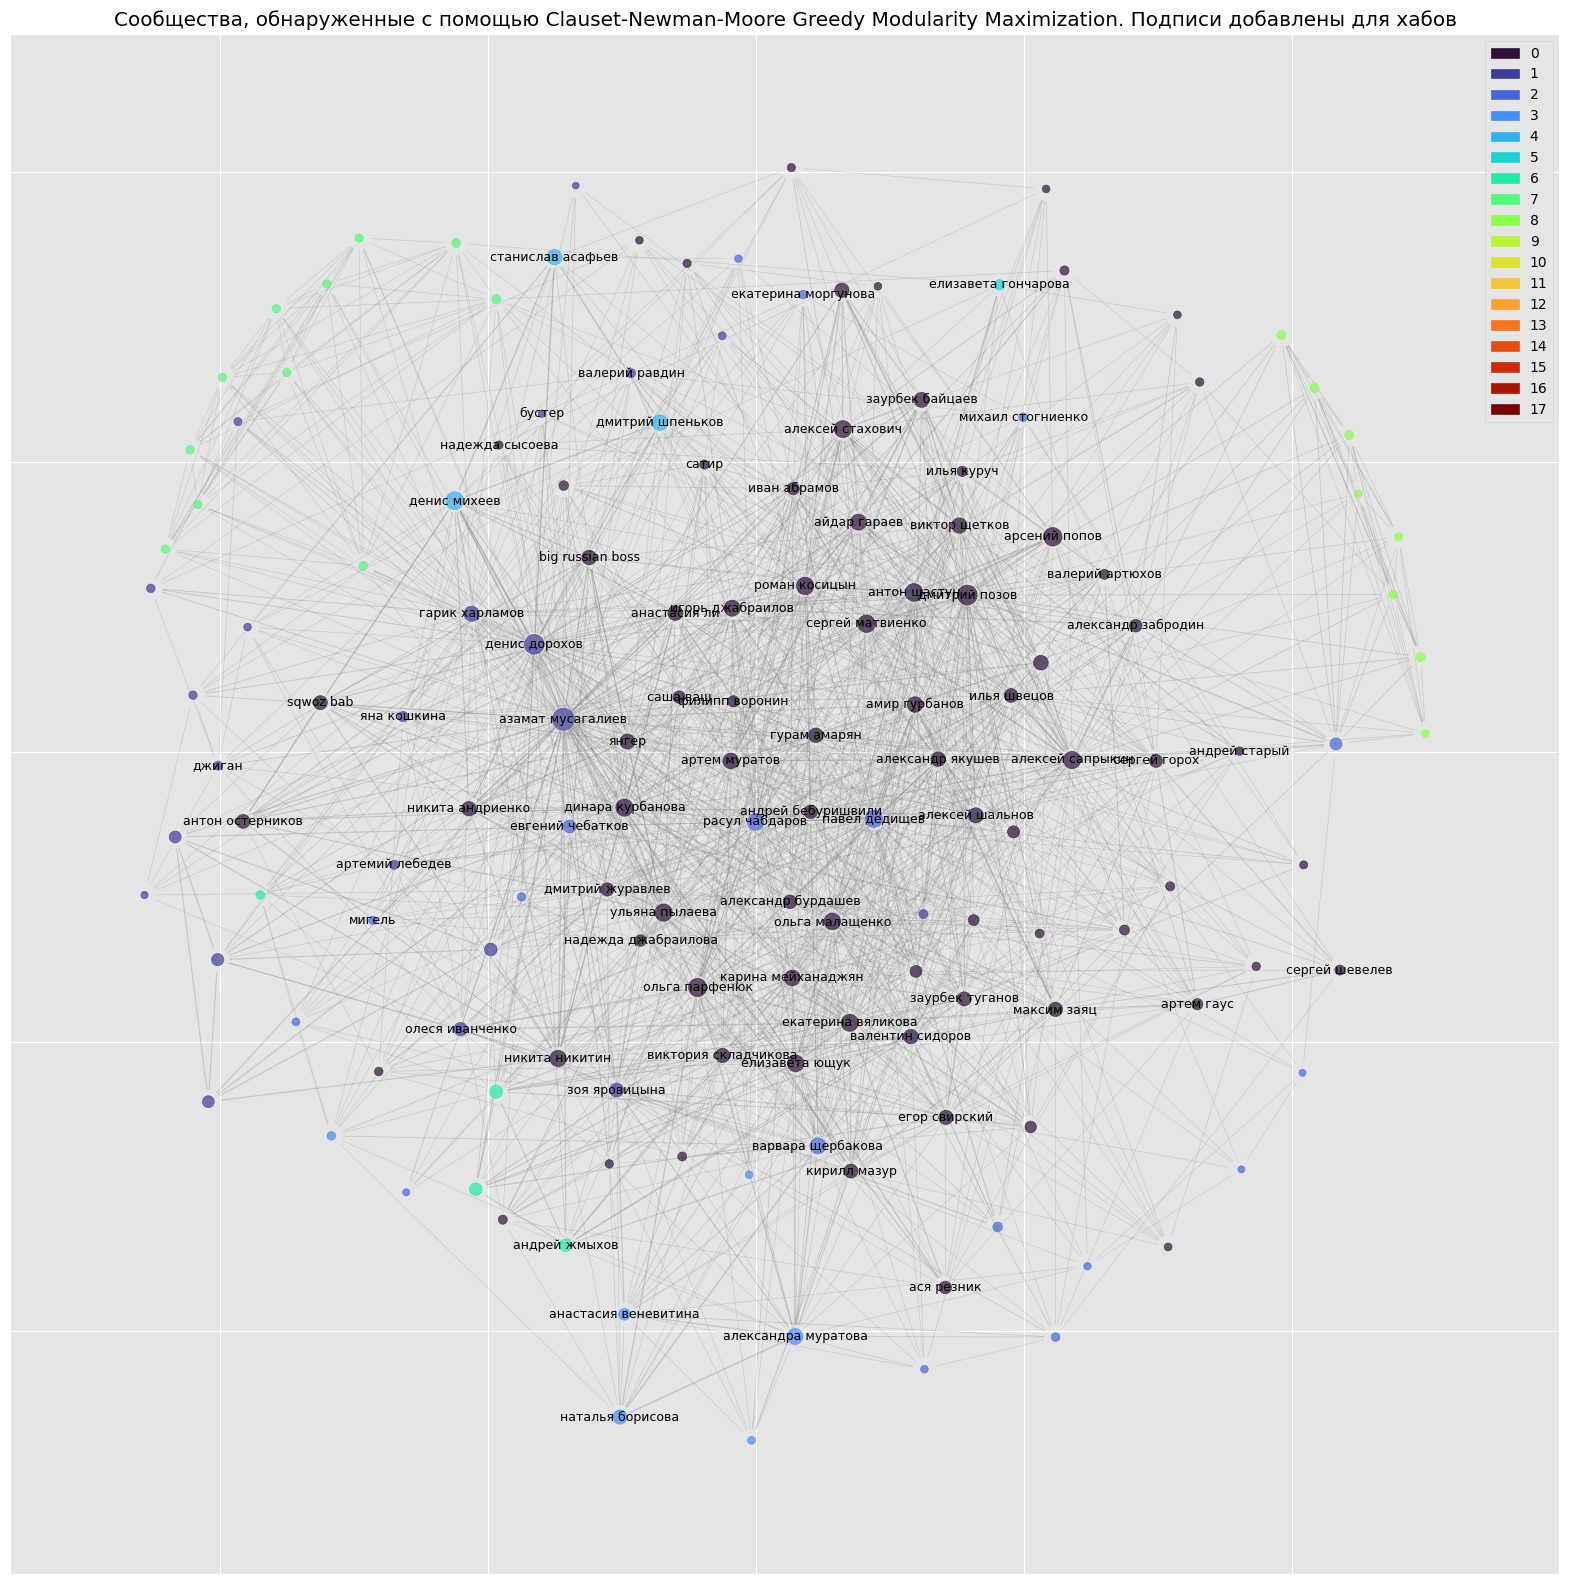

In [ ]:
# @title Визуализация сообществ, обнаруженных с помощью Clauset-Newman-Moore Greedy Modularity Maximization
import matplotlib.patches as mpatches
node_to_community = {}
for i, comm in enumerate(comm_greedy):
    for node in comm:
        node_to_community[node] = i

# создаем палитру по числу сообществ
cmap = plt.colormaps['turbo'].resampled(len(comm_greedy))

# назначаем цвет каждой вершине
cat_colors = dict(zip(list(range(len(comm_greedy))), cmap.colors))
node_colors = (pd.Series({n: cat_colors[comm_i] for comm_i, nodes in enumerate(comm_greedy) for n in nodes})
 .reindex(G_vis.nodes)
)

# рисуем граф
labels = {}
for node in G_vis.nodes():
    if node in hubs:
        labels[node] = node

edges_to_draw = []
for e in G_vis.edges:
    if e[0] != e[1]:
        edges_to_draw.append(e)
plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_vis, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_vis.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
nx.draw_networkx_edges(G_vis, pos, edgelist=edges_to_draw, arrows=True, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_vis, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_vis, pos,labels,font_size=9,font_color='black')

plt.legend(handles=[mpatches.Patch(color=c, label=label)
                    for label, c in cat_colors.items()],
           bbox_to_anchor=(1, 1))

plt.title("Сообщества, обнаруженные с помощью Clauset-Newman-Moore Greedy Modularity Maximization. Подписи добавлены для хабов")
plt.show();

Поскольку визуализацию выше довольно сложно читать, покажем сообщества отдельно.

In [ ]:
print(f"Обнаружено {len(comm_greedy)} сообществ:")
for i, comm in enumerate(comm_greedy):
    print(f"Сообщество №{i}\t({len(comm)} человек):\t Хабы: {', '.join(list(filter(lambda x: x in hubs, comm)))}")
    # print(f"Сообщество №{i}\t({len(comm)} человек)")

Обнаружено 18 сообществ:
Сообщество №0	(184 человек):	 Хабы: сергей горох, елизавета ющук, гурам амарян, александр бурдашев, артем муратов, сатир, ольга парфенюк, кирилл мазур, заурбек байцаев, илья швецов, иван абрамов, сергей шевелев, арсений попов, надежда сысоева, заурбек туганов, вячеслав чепурченко, дарья мартыненко, егор свирский, виктор щетков, карина мейханаджян, алексей стахович, андрей старый, никита андриенко, надежда джабраилова, саша ваш, динара курбанова, big russian boss, сергей матвиенко, ася резник, никита никитин, янгер, ирина мягкова, sqwoz bab, андрей бебуришвили, татьяна клац, айдар гараев, максим заяц, игорь джабраилов, илья куруч, дмитрий позов, екатерина вяликова, роман косицын, сергей зорик, александр забродин, евгения гольц, артем гаус, виктория складчикова, алина фоменко, алексей шальнов, ольга малащенко, анастасия ли, александр якушев, валерий артюхов, ульяна пылаева, алексей сапрыкин, антон шастун, амир гурбанов, марк сергиенко, дмитрий журавлев, антон ост

Алгоритм обнаружил 3 особенно крупных сообщества. Сообщество 0 объединяет несколько соведущих:

Во главе Сообщества 2 Азамат Мусагалиев, Денис Дорохов и Гарик Харламов -- совместно они ведут шоу "Кстати", которое является топ-7 по количеству выпусков (91 эпизод), и где приняло участие 312 гостей -- максимальное количество.

Визуализируем сообщества и подпишем топ-20 ее членов по степени вершины. Красным выделены хабы.

Graph with 148 nodes and 749 edges


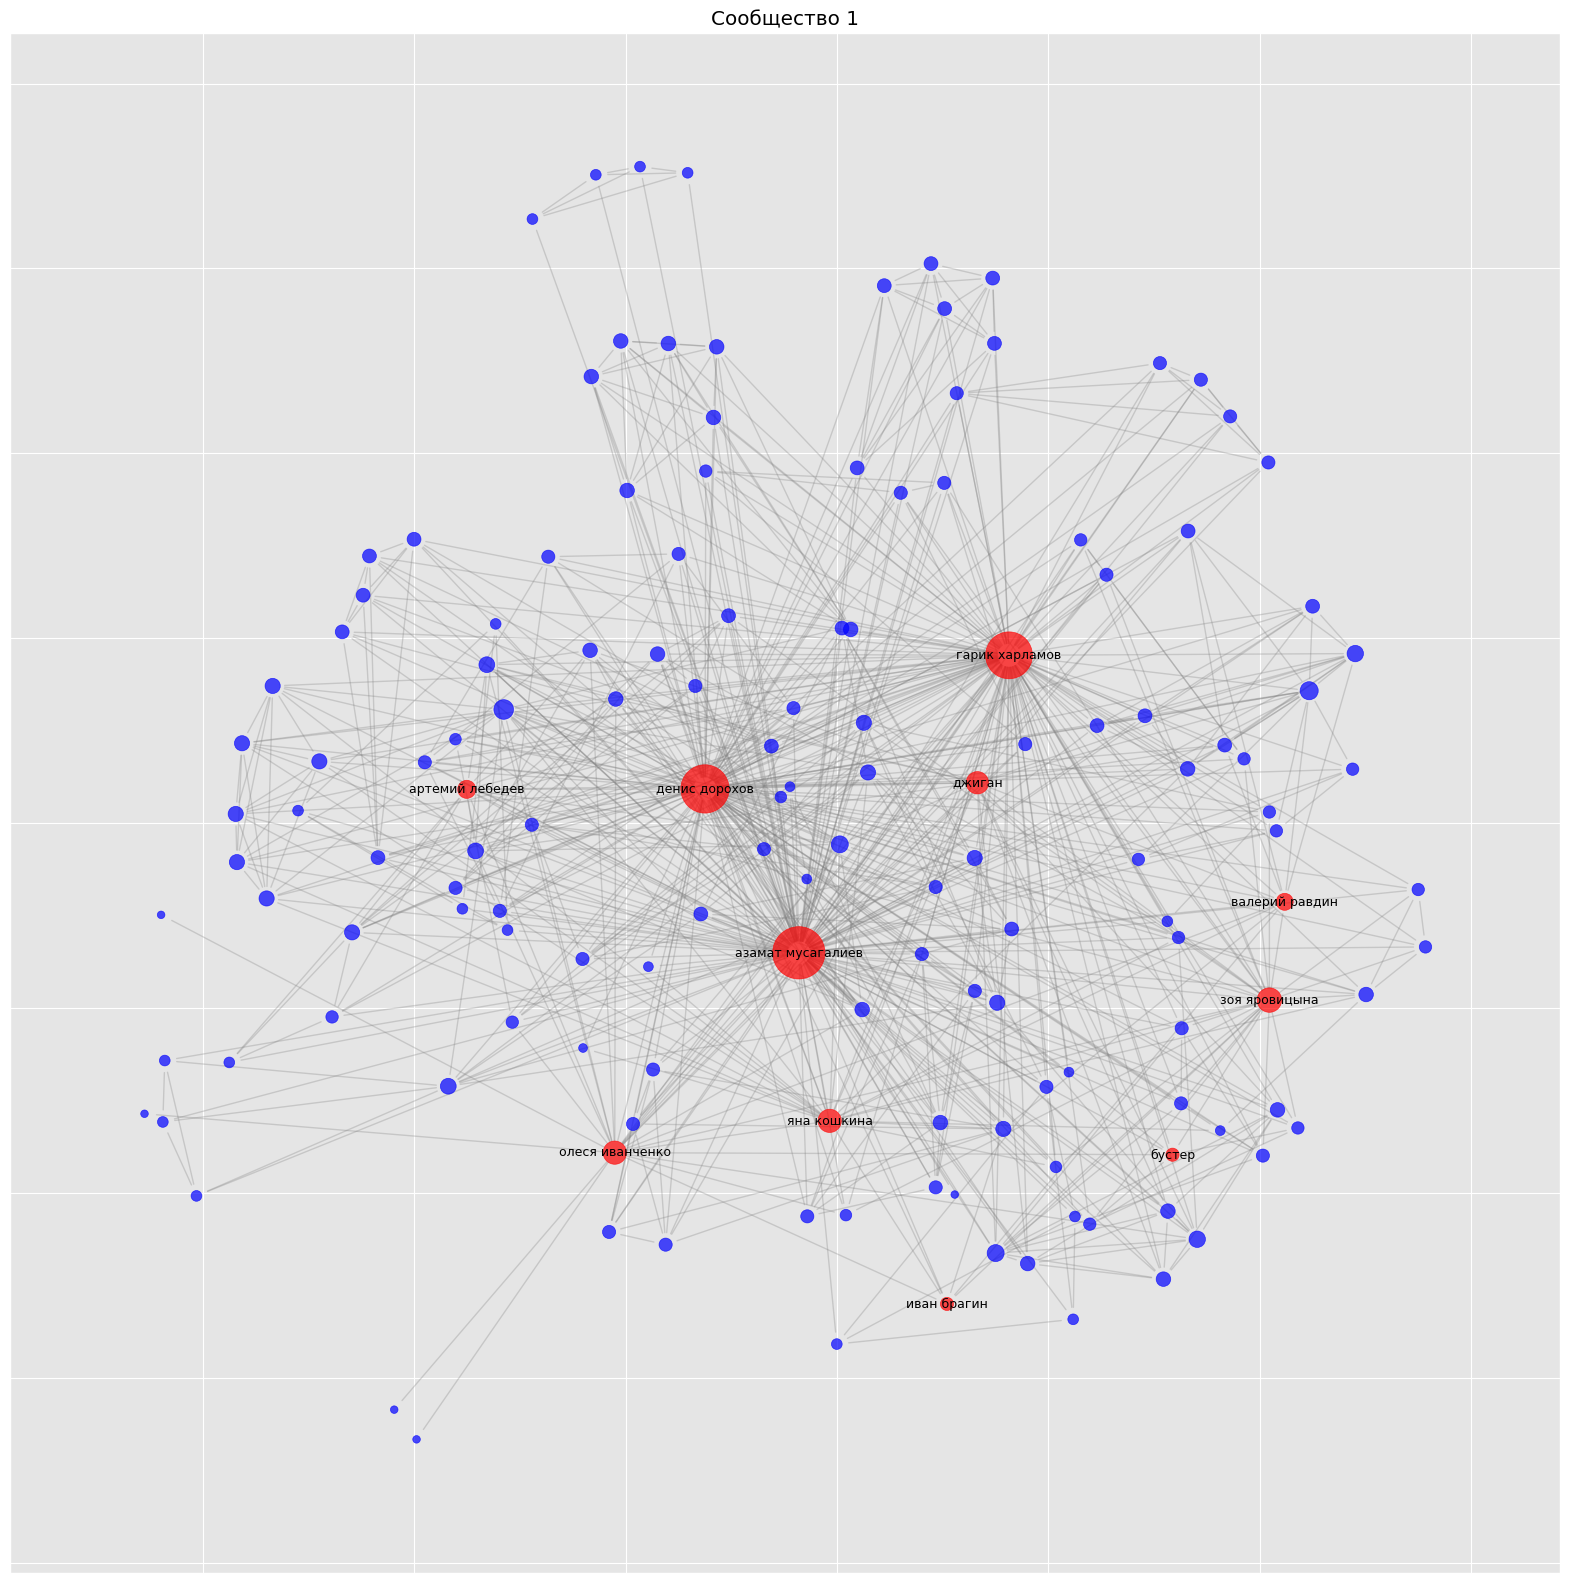

In [ ]:
COMMUNITY_NUM = 1 # @param {"type":"integer"}

visualize_community(COMMUNITY_NUM, comm_greedy, annotated_degree_min_threshold=hub_degree_threshold)

#### Louvain method

In [ ]:
# определяем сообщества
comm_louvian = nx.community.louvain_communities(G, weight='count', seed=42)
print('Количество сообществ по Louvain method:', len(comm_louvian))
# считаем модулярность
modularity_score = nx.community.modularity(G, comm_louvian, weight='count')
print('Модулярность по Louvain method', round(modularity_score,2))

Количество сообществ по Louvain method: 19
Модулярность по Louvain method 0.43


Значение модулярности выше предыдущего значения и говорит о более четкой сформированности сообществ.

Визуализируем

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning:

Creating legend with loc="best" can be slow with large amounts of data.



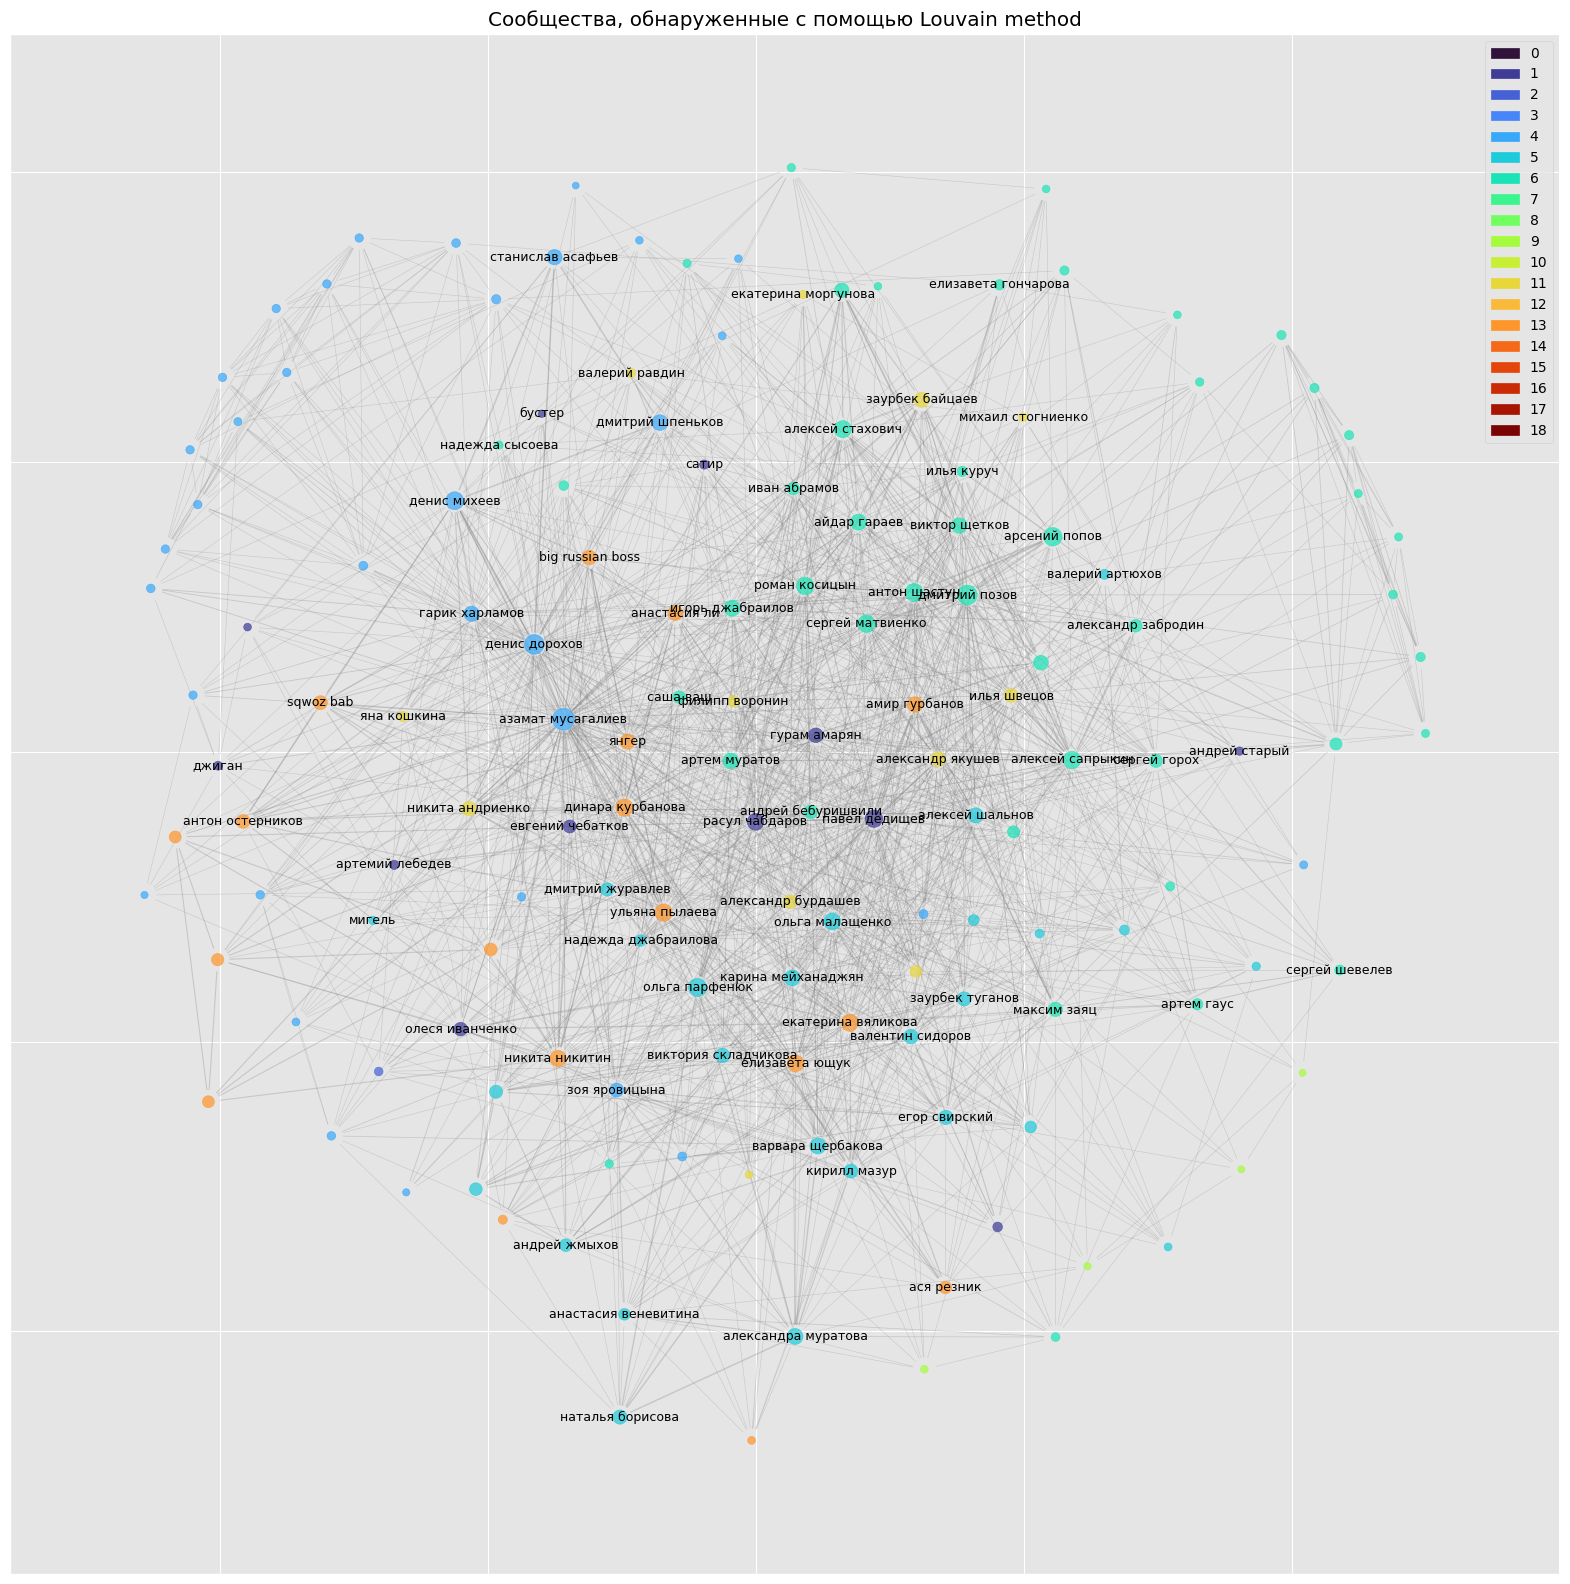

In [ ]:
node_to_community = {}
for i, comm in enumerate(comm_louvian):
    for node in comm:
        node_to_community[node] = i

# создаем палитру по числу сообществ
cmap = plt.colormaps['turbo'].resampled(len(comm_louvian))

# назначаем цвет каждой вершине
cat_colors = dict(zip(list(range(len(comm_louvian))), cmap.colors))
node_colors = (pd.Series({n: cat_colors[comm_i] for comm_i, nodes in enumerate(comm_louvian) for n in nodes})
 .reindex(G_vis.nodes)
)

# рисуем граф
labels = {}
for node in G_vis.nodes():
    if node in hubs:
        labels[node] = node

edges_to_draw = []
for e in G_vis.edges:
    if e[0] != e[1]:
        edges_to_draw.append(e)
plt.figure(figsize=(20,20))

nx.draw_networkx_nodes(G_vis, pos, node_size=[np.log(x)**3 + 20 for x in dict(G_vis.degree(weight='count')).values()], alpha=0.7, node_color=node_colors)
nx.draw_networkx_edges(G_vis, pos, edgelist=edges_to_draw, arrows=True, edge_color='gray', width=[(np.log(x)+2)/5 for x in list(nx.get_edge_attributes(G_vis, 'count').values())], alpha=0.3)
nx.draw_networkx_labels(G_vis, pos,labels,font_size=9,font_color='black')

plt.legend(handles=[mpatches.Patch(color=c, label=label)
                    for label, c in cat_colors.items()],
           bbox_to_anchor=(1, 1))

plt.title("Сообщества, обнаруженные с помощью Louvain method")
plt.show();

In [ ]:
print(f"Обнаружено {len(comm_louvian)} сообществ:")
for i, comm in enumerate(comm_louvian):
    print(f"Сообщество №{i}\t({len(comm)} человек):\t Хабы: {', '.join(list(filter(lambda x: x in hubs, comm)))}")
    # print(f"Сообщество №{i}\t({len(comm)} человек)")

Обнаружено 19 сообществ:
Сообщество №0	(6 человек):	 Хабы: 
Сообщество №1	(123 человек):	 Хабы: джиган, расул чабдаров, томас гайсанов, артемий лебедев, гурам амарян, сатир, илья соболев, павел дедищев, артем винокур, олеся иванченко, андрей старый, бустер, евгений чебатков
Сообщество №2	(177 человек):	 Хабы: эмир кашоков, алексей щербаков, илья макаров, нурлан сабуров, сергей детков, всеволод ловкачев, тамби масаев, рустам рептилоид
Сообщество №3	(7 человек):	 Хабы: евгений тасенков, антон истомин
Сообщество №4	(361 человек):	 Хабы: станислав асафьев, денис михеев, денис дорохов, чермен качмазов, зоя яровицына, дмитрий шпеньков, тимур батрутдинов, азамат мусагалиев, гарик харламов
Сообщество №5	(155 человек):	 Хабы: наталья борисова, ольга парфенюк, кирилл мазур, михаил лавров, заурбек туганов, мигель, вячеслав чепурченко, егор свирский, вадим постильный, карина мейханаджян, надежда джабраилова, варвара щербакова, ирина мягкова, александра муратова, анастасия веневитина, руслан мухаме

Graph with 177 nodes and 700 edges


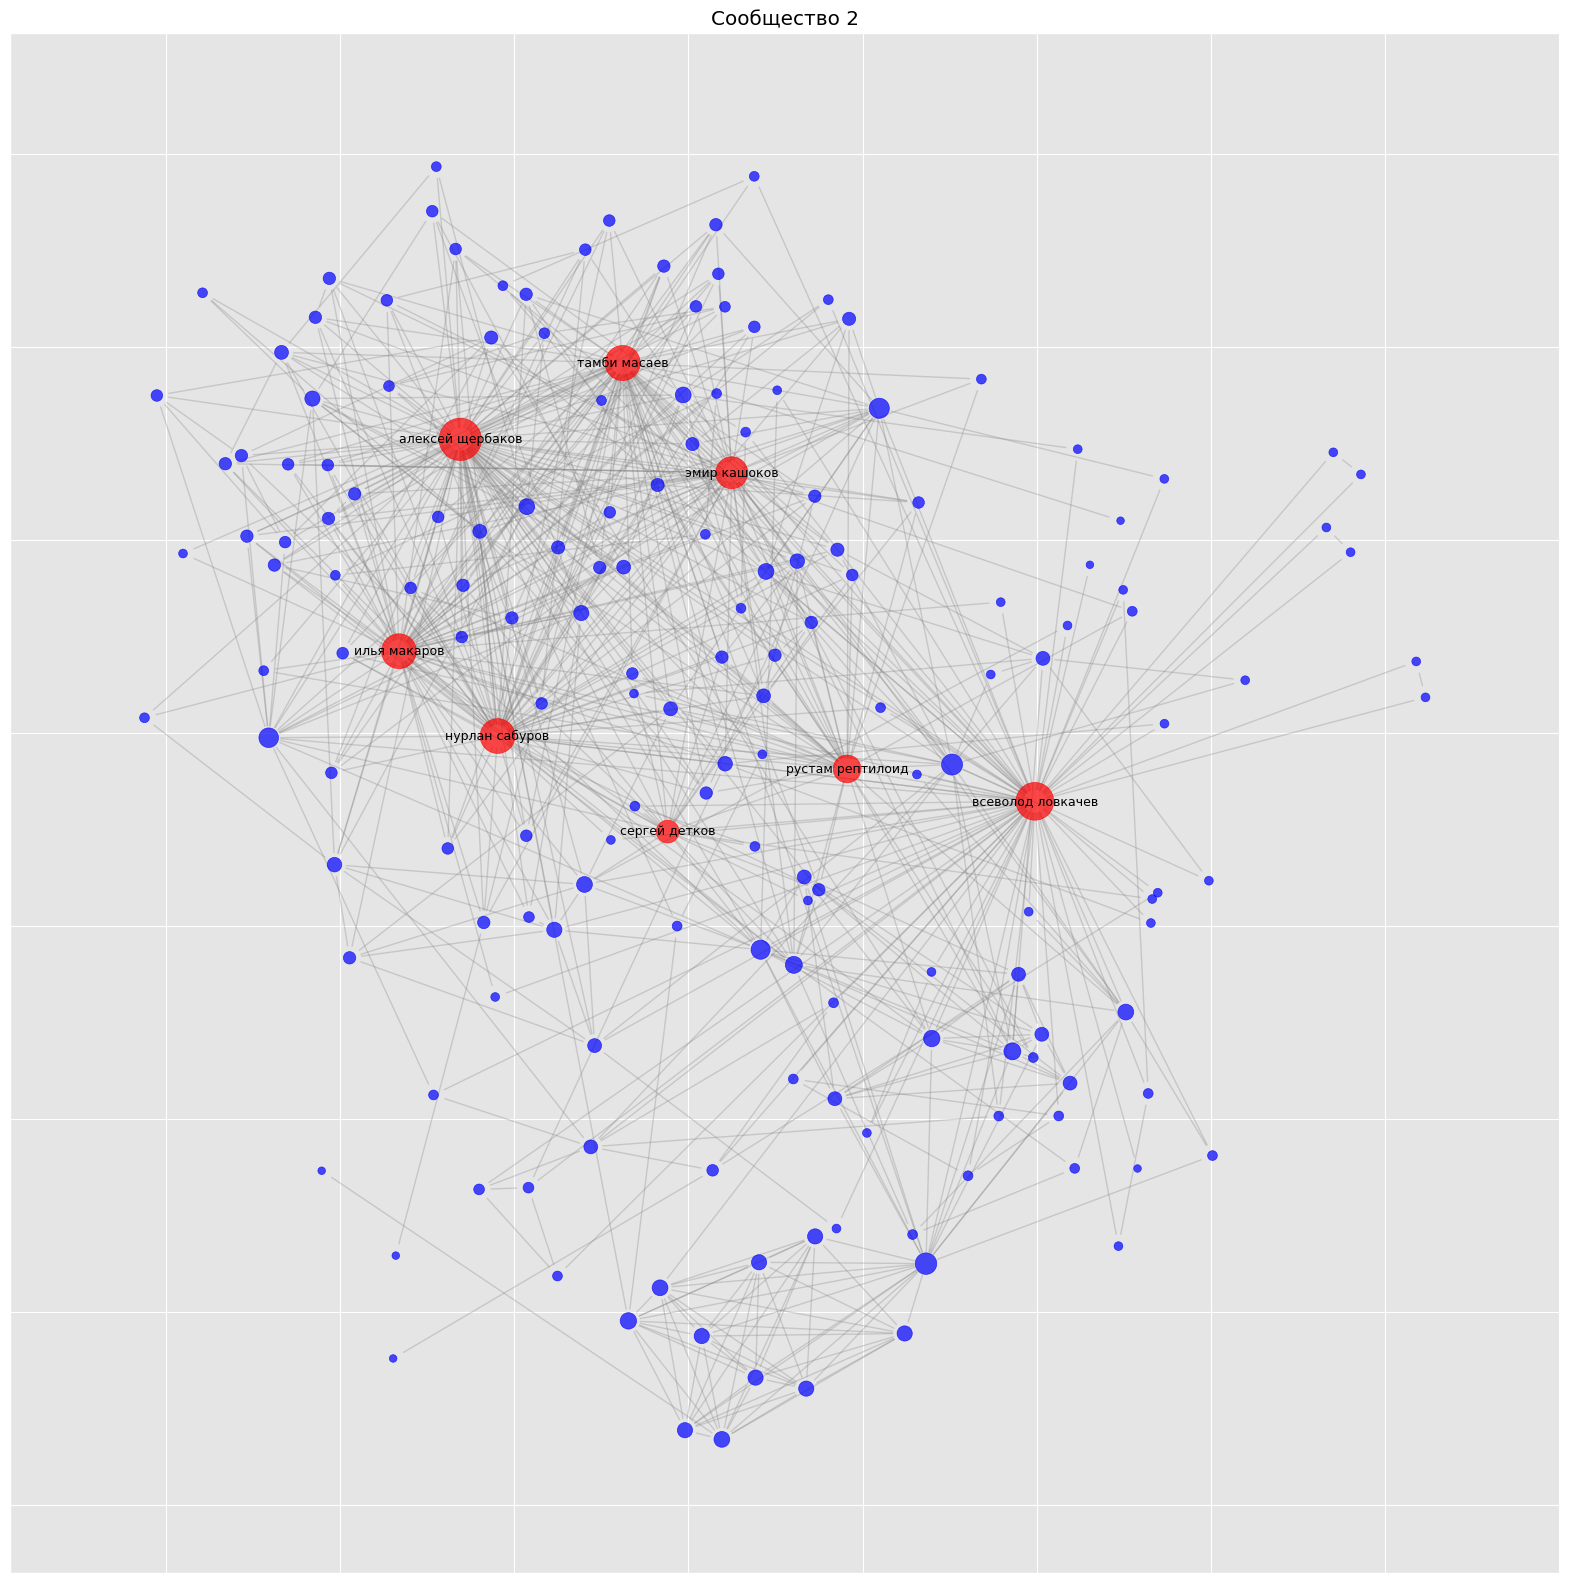

In [ ]:
COMMUNITY_NUM = 2 # @param {"type":"integer"}

visualize_community(COMMUNITY_NUM, comm_louvian)

In [ ]:
df.groupby(['show_title'])['hosts_str'].value_counts().sort_values(ascending=False)

show_title                        hosts_str                                                            
Контакты                          антон шастун                                                             131
Большое шоу                       азамат мусагалиев                                                        113
Громкий вопрос                    арсений попов,дмитрий позов,сергей матвиенко,антон шастун                109
Женский форум                     ольга парфенюк,варвара щербакова,наталья борисова,александра муратова     99
Шоу Истории                       арсений попов,дмитрий позов,сергей матвиенко,антон шастун                 92
                                                                                                          ... 
Спортивные и футбольные зашквары  дмитрий позов,игорь джабраилов,алексей стахович,роман косицын              1
                                  игорь джабраилов,алексей стахович                                          1
Фастмуд                           ольга парфенюк,варвара щербакова,наталья борисова,александра муратова      1
Хоумис                            дмитрий журавлёв                                                           1
Это хит                           дмитрий позов,ольга малащенко                                              1
Name: count, Length: 238, dtype: int64

In [ ]:
G_strong.edges

EdgeView([('антон шастун', 'роман косицын'), ('антон шастун', 'елизавета гончарова'), ('сергей матвиенко', 'дмитрий позов'), ('дмитрий позов', 'сергей горох'), ('дмитрий позов', 'игорь джабраилов'), ('сергей горох', 'сергей шевелев'), ('сергей горох', 'максим заяц'), ('сергей шевелев', 'максим заяц'), ('гурам амарян', 'расул чабдаров'), ('гурам амарян', 'артем винокур'), ('расул чабдаров', 'евгений чебатков'), ('артем винокур', 'павел дедищев'), ('азамат мусагалиев', 'гарик харламов'), ('гарик харламов', 'игорь джабраилов'), ('александра муратова', 'варвара щербакова'), ('александра муратова', 'наталья борисова'), ('варвара щербакова', 'ольга парфенюк'), ('наталья борисова', 'ольга парфенюк'), ('денис михеев', 'денис дорохов'), ('денис дорохов', 'дмитрий шпеньков'), ('денис дорохов', 'станислав асафьев'), ('дмитрий шпеньков', 'станислав асафьев'), ('антон истомин', 'евгений тасенков')])

In [ ]:
for d in G.edges(data=True):
    if (d[0]=='арсений попов' and d[1]=='дмитрий позов') or (d[1]=='арсений попов' and d[0]=='дмитрий позов'):
        print(d)

('дмитрий позов', 'арсений попов', {'count': 1})


In [ ]:
interactions.head()

,count,left,right
0,285,антон шастун,сергей матвиенко
1,6,антон шастун,александр забродин
2,1,сергей матвиенко,александр забродин
3,1,сергей горох,валерий равдин
4,100,гурам амарян,расул чабдаров


In [ ]:
min_shared_shows = 10

G_strong = nx.Graph()

for i, row in interactions.iterrows():
    u, v, count = row['left'], row['right'], row['count']
    if count >= min_shared_shows:
        G_strong.add_edge(u, v, weight=count)

# найти максимальные клики
cliques = list(nx.find_cliques(G_strong))

# Оставить только клики, где больше 3 людей
large_cliques = [clique for clique in cliques if len(clique) >= 3]

print(f"Клик, в которых >=3 членов: {len(large_cliques)}")

Клик, в которых >=3 членов: 81


Cliques identify sets of participants in which every pair has directly collaborated at least once. Because this requirement is strict, cliques may be smaller, more numerous, and more overlapping than the intuitive recurring teams or show casts. Therefore, cliques are used as local indicators of dense collaboration, while weighted community detection is used to identify broader groups of frequently collaborating participants.

In [ ]:
large_cliques

[['павел тихомиров',
  'мария маркова',
  'алексей ильин',
  'александр пташенчук',
  'тимур бабъяк'],
 ['александр ни', 'игорь джабраилов', 'чермен качмазов', 'зоя яровицына'],
 ['сергей шевелев',
  'максим заяц',
  'сергей горох',
  'сергей матвиенко',
  'антон шастун',
  'дмитрий позов'],
 ['сергей шевелев', 'максим заяц', 'сергей горох', 'артем гаус'],
 ['дмитрий шнякин', 'дмитрий позов', 'алексей сапрыкин'],
 ['антон истомин', 'ньургун атаков', 'евгений тасенков', 'елена савкина'],
 ['тамби масаев',
  'алексей щербаков',
  'илья макаров',
  'эмир кашоков',
  'нурлан сабуров',
  'рустам рептилоид'],
 ['андрей бебуришвили',
  'зоя яровицына',
  'саша ваш',
  'игорь джабраилов',
  'павел дедищев'],
 ['андрей бебуришвили',
  'зоя яровицына',
  'саша ваш',
  'игорь джабраилов',
  'иван абрамов'],
 ['андрей бебуришвили',
  'зоя яровицына',
  'саша ваш',
  'игорь джабраилов',
  'филипп воронин'],
 ['денис михеев', 'рустам аюпов', 'артём павлов'],
 ['денис михеев', 'дмитрий шпеньков', 'ст